In [1]:
##### JupytherNotebook to characterize intergenic TRs (regions of interest = roi) in Methanosarcina genomes in terms of neighboring genes and their predicted function (based on kofam-scan). The pipeline compares bed files of the tandem_repeats.py with gbff files of the genomes. It only includes intergenic TRs in the analysis by filtering out TRs that overlap or are within ORFs. #####
##### Functional enrichment and genomic capture rates were calculated using a pooled pangenome approach. This allowed for the identification of conserved genomic associations across the genus while accounting for the global density of regulatory regions. #####
##### To avoid phylogenetic bias, genomes were dereplicated at 99% ANI, resulting in 28 representative lineages. Functional enrichment was assessed using a permutation test with FDR correction. Despite lower absolute counts, identified KOs represent high-confidence associations conserved across diverse genomic backgrounds. #####

In [21]:
import pandas as pd
import pyranges as pr
import numpy as np
from scipy.stats import fisher_exact
import os
import re
import gzip
from Bio import SeqIO
from collections import defaultdict
from typing import List, Dict, Tuple
from statsmodels.stats.multitest import multipletests
from scipy.stats import binomtest
import matplotlib.pyplot as plt
import seaborn as sns
from collections import * 
import glob
from Bio.SeqFeature import SeqFeature, FeatureLocation
import subprocess
import json

In [3]:
##############################
### generate KEGG database ###
##############################

database = list()
for _, v in pd.read_json("2026-03-10_ko00001.json").iterrows():
    d = v["children"]
    cat_1 = d["name"]
    for child_1 in d["children"]:
        cat_2 = child_1["name"] # Module?
        for child_2 in child_1["children"]:
            cat_3 = child_2["name"]
            if "children" in child_2:
                for child_3 in child_2["children"]:
                    cat_4 = child_3["name"]
                    fields = [cat_1, cat_2, cat_3, cat_4]
                    database.append(fields)
df_kegg = pd.DataFrame(database, columns=["Level_A", "Level_B", "Level_C", "Level_D"])

def parse_ko_identifiers(x):
    x = x.upper()
    kos = list()
    elements = x.split(" ")
    for word in elements:
        if word:

            conditions = [
                word[0] == "K",
                word[1:].isnumeric(),
                len(word) == 6,
            ]
            if all(conditions):
                kos.append(word)
    return set(kos)
df_kegg["Level_D-KOs"] = df_kegg["Level_D"].map(parse_ko_identifiers)


database_expanded = dict()
for i, row in df_kegg.iterrows():
    for id_ko in row["Level_D-KOs"]:
        database_expanded[id_ko] = row
df_kegg_expanded = pd.DataFrame(database_expanded).T
df_kegg_expanded.index.name = "KO"
df_kegg_expanded.columns = df_kegg_expanded.columns.map(lambda x: (x.split("-")[0], x))

for id_cat in ["Level_A", "Level_B", "Level_C"]:
    df_kegg_expanded[(id_cat, "ID")] = df_kegg_expanded[(id_cat, id_cat)].map(lambda x: x.split(" ")[0])
    df_kegg_expanded[(id_cat, "Name")] = df_kegg_expanded[(id_cat, id_cat)].map(lambda x: " ".join(x.split(" ")[1:]))

def f(x):
    if "; " in x:
        return x.split("; ")[1]
    else:
        return x
df_kegg_expanded[("Level_D", "Name")] = df_kegg_expanded[("Level_D", "Level_D")].map(f)
df_kegg_expanded.columns = df_kegg_expanded.columns.map(lambda x: (x[0], "Full") if x[0] == x[1] else x)
df_kegg_expanded = df_kegg_expanded.sort_index(axis=1)

# Flatten the MultiIndex and keep both Name and ID
df_kegg_flat = df_kegg_expanded.copy()
df_kegg_flat.columns = [f"{col[0]}_{col[1]}" for col in df_kegg_flat.columns]
df_kegg_flat = df_kegg_flat.reset_index()

# Select the descriptive columns AND the ID columns
cols_to_keep = [
    'KO', 
    'Level_A_ID', 'Level_A_Name', 
    'Level_B_ID', 'Level_B_Name', 
    'Level_C_ID', 'Level_C_Name', 
    'Level_D_Name' # Level D usually doesn't have a separate ID in this format (the KO is the ID)
]

df_kegg_final = df_kegg_flat[cols_to_keep].copy()

df_kegg_final.to_csv("2026-03-10_KEGG-db_ko00001.csv", index=False)

print(df_kegg_final)

           KO Level_A_ID                      Level_A_Name Level_B_ID  \
0      K00844      09180                 Brite Hierarchies      09182   
1      K12407      09160                    Human Diseases      09167   
2      K00845      09100                        Metabolism      09110   
3      K25026      09100                        Metabolism      09110   
4      K01810      09180                 Brite Hierarchies      09183   
...       ...        ...                               ...        ...   
28115  K07220      09190  Not Included in Pathway or Brite      09194   
28116  K07276      09190  Not Included in Pathway or Brite      09194   
28117  K07338      09190  Not Included in Pathway or Brite      09194   
28118  K07586      09190  Not Included in Pathway or Brite      09194   
28119  K07742      09190  Not Included in Pathway or Brite      09194   

                                            Level_B_Name Level_C_ID  \
0       Protein families: genetic information proces

In [4]:
### load in data
# Load KO terms (filtered for e-values < 0.001)
ko_df = pd.read_csv('/cluster/project/umbiol/projects/methanogens/methanosarcina/proteins/protein_clustering/all_proteomes/kofam_scan/2026-04-29_kofam-scan_annotations_top-hits_filtered.tsv', sep='\t') # Columns: protein_id, KO
# Load COG terms from eggnogmapper
cog_df = pd.read_csv('/cluster/project/umbiol/projects/methanogens/methanosarcina/proteins/protein_clustering/all_proteomes/eggnog_mapper/methanosarcina_proteins_eggnog.emapper.annotations.tsv', sep='\t') # Columns: protein_id, COG_category

# Merge them into a single annotation master table
annotations = pd.merge(ko_df, cog_df, on='protein_id', how='outer')
annotations = pd.merge(annotations, df_kegg_final, on='KO', how='left')

# dir
results = []

In [5]:
#########################
####### FUNCTIONS #######
#########################

# --- 1. UTILITY FUNCTIONS ---

def list_files_with_ext(dir_path: str, exts: List[str]) -> List[str]:
    exts_lower = {e.lower() for e in exts}
    out = []
    if not os.path.exists(dir_path): return []
    for fn in os.listdir(dir_path):
        fp = os.path.join(dir_path, fn)
        if os.path.isfile(fp):
            if any(fn.lower().endswith(e) for e in exts_lower):
                out.append(fp)
    return sorted(out)

def stem(path: str) -> str:
    base = os.path.basename(path)
    # Extract GCA/GCF accession using regex for higher precision
    match = re.search(r'(GC[AF]_\d+)', base)
    return match.group(1) if match else base.split('.')[0]

def get_best_match(target_stem: str, candidate_paths: List[str]) -> str:
    for path in candidate_paths:
        if target_stem in stem(path):
            return path
    return None

def pair_files_robustly(bed_files, gbk_files):
    pairs = []
    for bed in bed_files:
        b_stem = stem(bed)
        match_gbk = get_best_match(b_stem, gbk_files)
        if match_gbk:
            pairs.append({"prefix": b_stem, "bed": bed, "gbk": match_gbk})
    return pairs

# --- 2. GENOMIC PARSING LOGIC ---

def get_cds_locations(gbk_path):
    """Returns a list of CDS dicts with coordinates."""
    cds_list = []
    with gzip.open(gbk_path, "rt") as handle:
        for record in SeqIO.parse(handle, "genbank"):
            for feat in record.features:
                if feat.type == "CDS":
                    p_id = feat.qualifiers.get('protein_id', [None])[0] or feat.qualifiers.get('locus_tag', [None])[0]
                    if p_id:
                        p_id = re.sub(r'^(cds-|protein_|gene-)', '', p_id)
                        cds_list.append({
                            'chrom': record.id,
                            'start': int(feat.location.start),
                            'end': int(feat.location.end),
                            'strand': feat.location.strand,
                            'protein_id': p_id
                        })
    return cds_list

def find_neighbors(bed_path, cds_list):
    """Finds flanking genes for intergenic BED regions, excluding overlaps."""
    # Organize CDS by chromosome and sort by start
    chrom_cds = defaultdict(list)
    for c in cds_list:
        chrom_cds[c['chrom']].append(c)
    for chrom in chrom_cds:
        chrom_cds[chrom].sort(key=lambda x: x['start'])

    neighbor_results = []
    
    with open(bed_path, "r") as fh:
        for line in fh:
            if line.startswith(("#", "track", "browser")) or not line.strip(): continue
            parts = line.strip().split("\t")
            chrom, b_start, b_end = parts[0], int(parts[1]), int(parts[2])
            
            if chrom not in chrom_cds: continue
            
            # 1. Overlap Check (Exclude BED region if it touches any ORF)
            is_overlapping = False
            for cds in chrom_cds[chrom]:
                if not (b_end <= cds['start'] or b_start >= cds['end']):
                    is_overlapping = True
                    break
            if is_overlapping: continue
            
            # 2. Identify Flanking Neighbors
            # Find the gene immediately before and after this intergenic region
            upstream = None
            downstream = None
            
            for i, cds in enumerate(chrom_cds[chrom]):
                if cds['end'] <= b_start:
                    upstream = cds
                elif cds['start'] >= b_end:
                    downstream = cds
                    break # Found the first gene starting after the BED region
            
            if upstream:
                neighbor_results.append({**upstream, 'rel_pos': 'upstream', 'roi_start': b_start})
            if downstream:
                neighbor_results.append({**downstream, 'rel_pos': 'downstream', 'roi_start': b_start})
                
    return neighbor_results


In [6]:
#########################
##### MAIN EXECUTION ####
#########################

# Prepare file lists
all_bed = list_files_with_ext("/cluster/project/umbiol/projects/methanogens/methanosarcina/genomes/TR_output/raw_output/bed_files/", [".bed"])
all_gbk = list_files_with_ext("/cluster/project/umbiol/projects/methanogens/methanosarcina/raw_data_ncbi/geneBank_files/99_dereplicated/", [".gbff.gz", ".gbk.gz"])  ######## select '99_dereplicated/' dir for dereplicated dataset
file_pairs = pair_files_robustly(all_bed, all_gbk)

print(f"Paired {len(file_pairs)} genomes.")

final_neighbor_list = []

for pair in file_pairs:
    print(f"Processing {pair['prefix']}...")
    cds_data = get_cds_locations(pair['gbk'])
    neighbors = find_neighbors(pair['bed'], cds_data)
    
    if neighbors:
        df_tmp = pd.DataFrame(neighbors)
        df_tmp['genome_acc'] = pair['prefix']
        final_neighbor_list.append(df_tmp)

if final_neighbor_list:
    # 4. FINAL INTEGRATION
    master_neighbors = pd.concat(final_neighbor_list)
    
    # Merge with your merged annotations table
    # Ensure annotations['protein_id'] is a string
    results_df = pd.merge(master_neighbors, annotations, on='protein_id', how='inner')
    
    print(f"Final Associations: {len(results_df)}")
    results_df.to_csv("genomic_neighborhood_results.csv", index=False)
else:
    print("No non-overlapping intergenic regions found next to genes.")

Paired 28 genomes.
Processing GCA_000007345...
Processing GCA_000969905...
Processing GCA_000969945...
Processing GCA_000969965...
Processing GCA_000969985...
Processing GCA_000970045...
Processing GCA_000970085...
Processing GCA_000970145...
Processing GCA_000970185...
Processing GCA_000970265...
Processing GCA_000970285...
Processing GCA_000970305...
Processing GCA_000979295...
Processing GCA_000979385...
Processing GCA_000979455...
Processing GCA_000979975...
Processing GCA_001027005...
Processing GCA_001304615...
Processing GCA_003584605...
Processing GCA_010706455...
Processing GCA_020804205...
Processing GCA_020804225...
Processing GCA_028692935...
Processing GCA_028693135...
Processing GCA_028705965...
Processing GCA_030247745...
Processing GCA_034331585...
Processing GCA_035390745...
Final Associations: 6885


In [7]:
# 1. Define key columns to keep
key_cols = [
    'genome_acc', 'chrom', 'roi_start', 'rel_pos', 
    'protein_id', 'strand', 'KO', 'KO_definition', 
    'COG_category', 'Description', 'Preferred_name', 'PFAMs'
]

# 2. Select columns and handle missing COG values
clean_results_df = results_df[key_cols].copy()

# Fill NaN COG categories with a placeholder string to avoid the ValueError
clean_results_df['COG_category'] = clean_results_df['COG_category'].fillna('')

# 3. Explode COG categories (e.g., 'JGE' becomes three rows: 'J', 'G', 'E')
# We strip whitespace and only split if the string isn't empty
clean_results_df['COG_category'] = clean_results_df['COG_category'].apply(lambda x: list(x) if x else [None])
clean_results_df = clean_results_df.explode('COG_category')

# 4. Filter for valid single-letter COG categories
# na=False ensures that rows with None/NaN are dropped without crashing
#is_alpha = clean_results_df['COG_category'].str.isalpha() == True
#clean_results_df = clean_results_df[is_alpha].copy()
clean_results_df = pd.merge(clean_results_df, df_kegg_final, on='KO', how='left')

clean_results_df.to_csv("cleaned_neighbors_metadata.tsv", sep='\t', index=False)

print(f"Cleaned associations: {len(clean_results_df)}")
print(clean_results_df.head())

Cleaned associations: 6946
      genome_acc       chrom  roi_start     rel_pos  protein_id  strand  \
0  GCA_000007345  AE010299.1       1979    upstream  AAM03455.1      -1   
1  GCA_000007345  AE010299.1      52970  downstream  AAM03496.1       1   
2  GCA_000007345  AE010299.1     310092    upstream  AAM03708.1       1   
3  GCA_000007345  AE010299.1     310092  downstream  AAM03709.1       1   
4  GCA_000007345  AE010299.1     321943    upstream  AAM03717.1       1   

       KO                                      KO_definition COG_category  \
0  K10725           archaeal cell division control protein 6            L   
1  K03265             peptide chain release factor subunit 1            J   
2  K21029  molybdopterin-synthase adenylyltransferase [EC...            H   
3     NaN                                                NaN            -   
4  K17884  archaetidylinositol phosphate synthase [EC:2.7...            I   

                                         Description Prefer

In [8]:
def build_protein_genome_map_gzip_fixed(gbk_folder):
    """Maps proteins to the FILENAME (Genome) rather than the Contig ID."""
    mapping = {}
    files = [f for f in os.listdir(gbk_folder) if f.endswith((".gbk.gz", ".gbff.gz"))]
    
    print(f"Parsing {len(files)} gzipped GenBank files...")
    
    for file in files:
        genome_acc = file.replace(".gbff.gz", "").replace(".gbk.gz", "")
        path = os.path.join(gbk_folder, file)
        
        with gzip.open(path, "rt") as handle:
            for record in SeqIO.parse(handle, "genbank"):
                for feature in record.features:
                    if feature.type == "CDS":
                        pid = feature.qualifiers.get('protein_id', [None])[0]
                        ltag = feature.qualifiers.get('locus_tag', [None])[0]
                        
                        if pid: mapping[pid] = genome_acc
                        if ltag: mapping[ltag] = genome_acc
    
    return mapping

# --- 1. RUN MAPPING ---
gbk_path = "/cluster/project/umbiol/projects/methanogens/methanosarcina/raw_data_ncbi/geneBank_files/99_dereplicated/" 
protein_to_genome = build_protein_genome_map_gzip_fixed(gbk_path)

# --- 2. CAPTURE INITIAL STATS ---
initial_total_rows = len(annotations)
initial_unique_genes = annotations['protein_id'].nunique()

# --- 3. APPLY MAP AND CALCULATE STEP-BY-STEP STATS ---
annotations['genome_acc'] = annotations['protein_id'].map(protein_to_genome)

# Filter out unmapped NAs
annotations_filtered = annotations.dropna(subset=['genome_acc']).copy()
after_na_total_rows = len(annotations_filtered)
after_na_unique_genes = annotations_filtered['protein_id'].nunique()

# Deduplicate for physical background
annotations_physically_unique = annotations_filtered.drop_duplicates(subset=['protein_id'])
final_unique_genes = annotations_physically_unique['protein_id'].nunique()
unique_genomes = annotations_filtered['genome_acc'].nunique()

# --- 4. GBK FILE MATCH VERIFICATION ---
expected_genomes = set(f.replace(".gbff.gz", "").replace(".gbk.gz", "") 
                       for f in os.listdir(gbk_path) if f.endswith((".gbk.gz", ".gbff.gz")))
actual_matched_genomes = set(annotations_filtered['genome_acc'].unique())
unmatched_gbk_files = expected_genomes - actual_matched_genomes

# --- 5. PRINT STATISTICS ---
print("\n" + "="*50)
print("                FILTERING STATISTICS                ")
print("="*50)
print(f"1. Before filtering (Initial Data):")
print(f"   - Total rows: {initial_total_rows}")
print(f"   - Unique genes: {initial_unique_genes}")
print("-"*50)
print(f"2. After removing unmapped NAs:")
print(f"   - Total rows remaining: {after_na_total_rows}")
print(f"   - Unique genes remaining: {after_na_unique_genes}")
print(f"   - Lost due to no genome match: {initial_unique_genes - after_na_unique_genes} unique genes")
print("-"*50)
print(f"3. After removing duplicate protein IDs (Final):")
print(f"   - Unique genes remaining: {final_unique_genes}")
print(f"   - Duplicates removed: {after_na_total_rows - len(annotations_physically_unique)} rows")
print("-"*50)

print(f"4. GBK File Matching Verification:")
if len(unmatched_gbk_files) == 0:
    print(f"   ✅ Success! Every single one of the {len(expected_genomes)} GBK files matched at least one protein in your annotations.")
else:
    print(f"   ❌ WARNING: {len(unmatched_gbk_files)} GBK file(s) did NOT match any proteins in your annotations dataset!")
    print(f"   Unmatched Genomes: {', '.join(unmatched_gbk_files)}")
print("="*50 + "\n")

print(f"Background Cleaned: {final_unique_genes} unique proteins across {unique_genomes} genomes.")
print(f"Average CDS per genome: {final_unique_genes / unique_genomes:.0f}")

Parsing 28 gzipped GenBank files...

                FILTERING STATISTICS                
1. Before filtering (Initial Data):
   - Total rows: 332043
   - Unique genes: 332043
--------------------------------------------------
2. After removing unmapped NAs:
   - Total rows remaining: 85556
   - Unique genes remaining: 85556
   - Lost due to no genome match: 246487 unique genes
--------------------------------------------------
3. After removing duplicate protein IDs (Final):
   - Unique genes remaining: 85556
   - Duplicates removed: 0 rows
--------------------------------------------------
4. GBK File Matching Verification:
   ✅ Success! Every single one of the 28 GBK files matched at least one protein in your annotations.

Background Cleaned: 85556 unique proteins across 28 genomes.
Average CDS per genome: 3056


In [9]:
# --- STEP 1: Correct the Background (annotations) ---
# Map the genome_acc using our new Biopython lookup table
annotations['genome_acc'] = annotations['protein_id'].map(protein_to_genome)

# Filter: Keep ONLY proteins present in our 28 GenBank files
annotations_filtered = annotations.dropna(subset=['genome_acc']).copy()

# Deduplicate for a clean Physical Background (one row per protein)
annotations_physically_unique = annotations_filtered.drop_duplicates(subset=['protein_id'])

# Reporting the fix
total_after = annotations_physically_unique['protein_id'].nunique()
current_acc_count = annotations_filtered['genome_acc'].nunique()

print(f"Background Cleaned: {total_after} unique proteins across {current_acc_count} genomes.")
print(f"Average CDS per genome: {total_after / current_acc_count:.0f}")


# --- STEP 2: Prepare the Master Table (clean_results_df) ---
key_cols = [
    'genome_acc', 'chrom', 'roi_start', 'rel_pos', 
    'protein_id', 'strand', 'KO', 'KO_definition', 
    'COG_category', 'Description', 'Preferred_name', 'PFAMs'
]

# Create the Master (Un-exploded) Table
clean_results_df = results_df[key_cols].copy()

# Ensure KEGG hierarchy is merged
clean_results_df = pd.merge(clean_results_df, df_kegg_final, on='KO', how='left')

# Pre-generate KEGG Full Strings for both Observed and Filtered Background
# We use annotations_filtered here to ensure all possible annotation rows are available for stats
for df in [clean_results_df, annotations_filtered]:
    if 'Level_A_ID' in df.columns:
        df['Level_A_Full'] = df['Level_A_ID'].astype(str) + " " + df['Level_A_Name'].astype(str)
        df['Level_B_Full'] = df['Level_B_ID'].astype(str) + " " + df['Level_B_Name'].astype(str)
        df['Level_C_Full'] = df['Level_C_ID'].astype(str) + " " + df['Level_C_Name'].astype(str)

clean_results_df.to_csv("master_neighbors_clean.tsv", sep='\t', index=False)


# --- STEP 3: Create the COG-Exploded Table ---
cog_exploded_df = clean_results_df.copy()
cog_exploded_df['COG_category'] = cog_exploded_df['COG_category'].fillna('')

# Explode logic: JGE -> [J, G, E]
cog_exploded_df['COG_category'] = cog_exploded_df['COG_category'].apply(
    lambda x: list(str(x)) if x and str(x).strip() != "" else [None]
)
cog_exploded_df = cog_exploded_df.explode('COG_category')

cog_exploded_df.to_csv("cog_exploded_neighbors.tsv", sep='\t', index=False)

print(f"\nSUCCESS:")
print(f"1. Master Table: {clean_results_df['protein_id'].nunique()} unique physical proteins.")
print(f"2. Background Table: {annotations_filtered['protein_id'].nunique()} unique proteins.")
print(f"3. Exploded Table: {len(cog_exploded_df)} functional assignments.")

# --- STEP 4: Calculate Final Summary Statistics ---

# 1. Number of total genes (Physical Background)
total_genes = annotations_physically_unique['protein_id'].nunique()

# 2. Number of total genes with KO annotation
# We filter the physically unique background for rows where 'KO' is not null
total_genes_with_ko = annotations_physically_unique[
    annotations_physically_unique['KO'].notna() & (annotations_physically_unique['KO'] != '-')
]['protein_id'].nunique()

# 3. Number of genes in TR neighborhood
# Based on your 'clean_results_df' which contains all proteins near TRs
tr_neighborhood_genes = clean_results_df['protein_id'].nunique()

# 4. Number of genes in TR neighborhood with KO annotation
tr_neighborhood_with_ko = clean_results_df[
    clean_results_df['KO'].notna() & (clean_results_df['KO'] != '-')
]['protein_id'].nunique()

# --- Print the Results ---
print("="*40)
print("FINAL DATASET SUMMARY")
print("="*40)
print(f"Total Genes (Background):              {total_genes:,}")
print(f"Total Genes with KO:                   {total_genes_with_ko:,} ({total_genes_with_ko/total_genes*100:.1f}%)")
print("-" * 40)
print(f"Genes in TR Neighborhood:              {tr_neighborhood_genes:,}")
print(f"Genes in TR Neighborhood with KO:      {tr_neighborhood_with_ko:,} ({tr_neighborhood_with_ko/tr_neighborhood_genes*100:.1f}%)")
print("="*40)

# Optional: Save these numbers to a small text file for your records
with open("dataset_coverage_summary.txt", "w") as f:
    f.write(f"Total_Genes: {total_genes}\n")
    f.write(f"Total_Genes_with_KO: {total_genes_with_ko}\n")
    f.write(f"TR_Neighborhood_Genes: {tr_neighborhood_genes}\n")
    f.write(f"TR_Neighborhood_with_KO: {tr_neighborhood_with_ko}\n")

Background Cleaned: 85556 unique proteins across 28 genomes.
Average CDS per genome: 3056

SUCCESS:
1. Master Table: 6209 unique physical proteins.
2. Background Table: 85556 unique proteins.
3. Exploded Table: 6946 functional assignments.
FINAL DATASET SUMMARY
Total Genes (Background):              85,556
Total Genes with KO:                   67,709 (79.1%)
----------------------------------------
Genes in TR Neighborhood:              6,209
Genes in TR Neighborhood with KO:      4,884 (78.7%)


In [10]:
#########################################################
###### Functional Enrichment & Depletion analysis: ######
#########################################################

# --- STEP 1: DEFINE DATASETS ---
# clean_results_df is your "Master" (one row per protein)
# cog_exploded_df is for COG analysis only

# Ensure clean_results_df has the KEGG Levels needed for the breakdown
for df_to_fix in [clean_results_df, annotations]:
    if 'Level_A_ID' in df_to_fix.columns:
        df_to_fix['Level_A_Full'] = df_to_fix['Level_A_ID'].astype(str) + " " + df_to_fix['Level_A_Name'].astype(str)
        df_to_fix['Level_B_Full'] = df_to_fix['Level_B_ID'].astype(str) + " " + df_to_fix['Level_B_Name'].astype(str)
        df_to_fix['Level_C_Full'] = df_to_fix['Level_C_ID'].astype(str) + " " + df_to_fix['Level_C_Name'].astype(str)

# --- STEP 2: DEFINE THE BREAKDOWN FUNCTION ---
def get_genome_breakdown(df, category_col):
    # Use nunique('protein_id') instead of size/count
    counts = df.groupby([category_col, 'genome_acc'])['protein_id'].nunique().reset_index()
    counts.columns = [category_col, 'genome_acc', 'count']
    
    # Format as: Genome [Count]
    counts['combined'] = counts['genome_acc'] + " [" + counts['count'].astype(str) + "]"
    
    # Group by the category (KO) and join with commas
    breakdown = counts.groupby(category_col)['combined'].apply(lambda x: ", ".join(x)).reset_index()
    breakdown.columns = ['Category', 'Source_Genomes']
    return breakdown

# --- STEP 3: GENERATE BREAKDOWNS ---
print("Generating Genome Breakdowns...")

# KO & KEGG levels use the Master (clean_results_df)
ko_breakdown = get_genome_breakdown(clean_results_df, 'KO')
level_a_breakdown = get_genome_breakdown(clean_results_df, 'Level_A_Full')
level_b_breakdown = get_genome_breakdown(clean_results_df, 'Level_B_Full')
level_c_breakdown = get_genome_breakdown(clean_results_df, 'Level_C_Full')

# COG uses the Exploded table
cog_breakdown = get_genome_breakdown(cog_exploded_df, 'COG_category')

# --- STEP 4: ADD GENOME BREADTH ---
for b_df in [ko_breakdown, cog_breakdown, level_a_breakdown, level_b_breakdown, level_c_breakdown]:
    b_df['Genome_Breadth'] = b_df['Source_Genomes'].apply(
        lambda x: len(str(x).split(',')) if x and str(x).strip() != "" else 0
    )

print("Breakdowns complete.")

Generating Genome Breakdowns...
Breakdowns complete.


In [11]:
########################################
####### Run the permutation test #######
########################################

def run_permutation_with_bh(observed_df, background_df, column_name, iterations=1000):
    """
    Two-sided permutation test including 'Unknown' for NAs/blanks/dashes
    and applying Benjamini-Hochberg FDR correction.
    """
    print(f"Running {iterations} iterations (Two-sided) for {column_name}...")

    # 1. Internal Helper to unify "Unknown" types (NaN, '', '-')
    def clean_unknowns(df, col):
        d = df.copy()
        # Ensure column exists; if not, return 'Unknown'
        if col not in d.columns:
            d[col] = 'Unknown'
            return d
        # Convert '-' and empty strings to NaN, then fill all NaNs with 'Unknown'
        d[col] = d[col].replace(['-', '', 'nan', 'NaN'], np.nan).fillna('Unknown')
        return d

    bg_clean = clean_unknowns(background_df, column_name)
    obs_df_clean = clean_unknowns(observed_df, column_name)
    
    # 2. Special handling for COG (only for the actual COG column)
    if column_name == 'COG_category':
        is_cog = (bg_clean[column_name] != 'Unknown')
        cogs = bg_clean[is_cog].copy()
        cogs[column_name] = cogs[column_name].apply(list)
        cogs = cogs.explode(column_name)
        others = bg_clean[~is_cog]
        bg_clean = pd.concat([cogs, others])

    # 3. Observed Stats
    obs_series = obs_df_clean[column_name].value_counts()
    obs_freqs = obs_df_clean[column_name].value_counts(normalize=True)
    n_samples = len(obs_df_clean)
    
    # 4. Iterative Null Distribution
    null_freqs_list = []
    for _ in range(iterations):
        sample = bg_clean.sample(n=n_samples, replace=True)
        null_freqs_list.append(sample[column_name].value_counts(normalize=True))
    
    null_df = pd.DataFrame(null_freqs_list).fillna(0)
    
    # 5. Calculate Statistics
    stats_list = []
    for cat in obs_freqs.index:
        if cat in null_df.columns:
            obs_f = obs_freqs[cat]
            null_dist = null_df[cat]
            mean_f = null_dist.mean()
            std_f = null_dist.std()
            
            z = (obs_f - mean_f) / std_f if std_f > 0 else 0
            p_up = ((null_dist >= obs_f).sum() + 1) / (iterations + 1)
            p_lo = ((null_dist <= obs_f).sum() + 1) / (iterations + 1)
            p_val = min(1.0, 2 * min(p_up, p_lo))
            
            stats_list.append({
                'Category': cat,
                'Observed_Count': int(obs_series[cat]),
                'Expected_Count': round(mean_f * n_samples, 2),
                'Z_score': round(z, 2),
                'P_value': p_val 
            })
    
    result_df = pd.DataFrame(stats_list)
    
    # 5. Benjamini-Hochberg Correction
    if not result_df.empty:
        _, adj_p, _, _ = multipletests(result_df['P_value'], method='fdr_bh')
        result_df['FDR_P_adj'] = adj_p
        
    result_df['Status'] = np.where(result_df['Z_score'] > 0, 'Enriched', 'Depleted')
    
    # 6. Formatting for Export
    for col in ['P_value', 'FDR_P_adj']:
        if col in result_df.columns:
            result_df[col] = result_df[col].apply(lambda x: '{:.4e}'.format(x))

    return result_df.sort_values('Z_score', ascending=False)


# --- EXECUTION: DATA PREP ---

# Ensure Level Full Strings exist in BOTH dataframes to prevent KeyErrors
for dataframe in [clean_results_df, annotations, cog_exploded_df]:
    if 'Level_A_ID' in dataframe.columns:
        dataframe['Level_A_Full'] = dataframe['Level_A_ID'].astype(str) + " " + dataframe['Level_A_Name'].astype(str)
        dataframe['Level_B_Full'] = dataframe['Level_B_ID'].astype(str) + " " + dataframe['Level_B_Name'].astype(str)
        dataframe['Level_C_Full'] = dataframe['Level_C_ID'].astype(str) + " " + dataframe['Level_C_Name'].astype(str)

# --- RE-RUN ANALYSIS ---

cog_stats_final = run_permutation_with_bh(cog_exploded_df, annotations, 'COG_category')
ko_stats_final = run_permutation_with_bh(clean_results_df, annotations, 'KO')
level_a_stats = run_permutation_with_bh(clean_results_df, annotations, 'Level_A_Full')
level_b_stats = run_permutation_with_bh(clean_results_df, annotations, 'Level_B_Full')
level_c_stats = run_permutation_with_bh(clean_results_df, annotations, 'Level_C_Full')

# --- GENERATE BREAKDOWNS ---

ko_breakdown = get_genome_breakdown(clean_results_df, 'KO')
cog_breakdown = get_genome_breakdown(cog_exploded_df, 'COG_category')
level_a_breakdown = get_genome_breakdown(clean_results_df, 'Level_A_Full')
level_b_breakdown = get_genome_breakdown(clean_results_df, 'Level_B_Full')
level_c_breakdown = get_genome_breakdown(clean_results_df, 'Level_C_Full')

# --- MERGE AND ADD BREADTH ---

final_outputs = []
stats_to_merge = [
    (ko_stats_final, ko_breakdown),
    (cog_stats_final, cog_breakdown),
    (level_a_stats, level_a_breakdown),
    (level_b_stats, level_b_breakdown),
    (level_c_stats, level_c_breakdown)
]

for stats_df, breakdown_df in stats_to_merge:
    if not stats_df.empty:
        # Merge source info
        m_df = pd.merge(stats_df, breakdown_df, on='Category', how='left')
        # Add Genome Breadth count (number of genomes present)
        m_df['Genome_Breadth'] = m_df['Source_Genomes'].apply(
            lambda x: len(str(x).split(',')) if x and str(x).strip() != "" else 0
        )
        final_outputs.append(m_df)
    else:
        final_outputs.append(stats_df)

# Final explicit re-assignment
ko_stats_final, cog_stats_final, level_a_stats, level_b_stats, level_c_stats = final_outputs

# --- SAVE TO TSV ---
cog_stats_final.to_csv("COG_two_sided_stats.tsv", sep='\t', index=False)
ko_stats_final.to_csv("KO_two_sided_stats.tsv", sep='\t', index=False)
level_a_stats.to_csv("KEGG_Level_A_Enrichment.tsv", sep='\t', index=False)
level_b_stats.to_csv("KEGG_Level_B_Enrichment.tsv", sep='\t', index=False)
level_c_stats.to_csv("KEGG_Level_C_Enrichment.tsv", sep='\t', index=False)

print("All analyses complete. Baseline physical density preserved.")

Running 1000 iterations (Two-sided) for COG_category...
Running 1000 iterations (Two-sided) for KO...
Running 1000 iterations (Two-sided) for Level_A_Full...
Running 1000 iterations (Two-sided) for Level_B_Full...
Running 1000 iterations (Two-sided) for Level_C_Full...
All analyses complete. Baseline physical density preserved.


In [12]:
#########################################
###### KO capture rates analysis: #######
#########################################

def calculate_ko_capture_stats_v6(observed_df, background_df):
    """
    Calculates KO capture stats including Source Genome counts and ROI Sequence diversity.
    Uses the GLOBAL physical background probability for the Binomial test.
    """
    # 1. Basic Frequency Counts (nunique ensures 1 protein = 1 count)
    ko_with_roi = observed_df.groupby('KO')['protein_id'].nunique()
    total_ko_counts = background_df.groupby('KO')['protein_id'].nunique()
    
    # 2. Global Probability (p) measured with ALL genes
    # This captures the true physical density (Observed neighbors / Total genome genes)
    total_genes_bg = background_df['protein_id'].nunique() 
    total_genes_obs = observed_df['protein_id'].nunique()
    prob_bg = total_genes_obs / total_genes_bg 
    
    results = []
    # --- LOOP START ---
    for ko, total in total_ko_counts.items():
        if str(ko).lower() in ['unknown', 'nan', '']: continue
        
        hits = ko_with_roi.get(ko, 0)
        capture_rate = (hits / total) * 100
        
        # Exact Binomial Test (Two-sided) vs the ~2.07% physical baseline
        res = binomtest(hits, n=total, p=prob_bg, alternative='two-sided')
        
        results.append({
            'KO': ko,
            'Observed_Hits': hits,           
            'Total_KO_in_Genomes': total,    
            'Capture_Rate_%': round(capture_rate, 2),
            'Exp_Capture_Rate_%': round(prob_bg * 100, 2), 
            'P_value_numeric': res.pvalue,   
            'Status': "Enriched" if (hits/total) > prob_bg else "Depleted",
            'Global_Genome_Density_p': round(prob_bg, 4)
        })
    # --- LOOP END ---
    
    stats_df = pd.DataFrame(results).sort_values('P_value_numeric')
    
    # 3. Add Genome Breadth (Total unique genomes containing this KO near a TR)
    breadth = observed_df.groupby('KO')['genome_acc'].nunique().reset_index()
    breadth.columns = ['KO', 'Genome_Presence_Count']
    
    # 4. Add Source Genome Detail (Formatted string of Genome [Count])
    # Uses the helper function defined in your previous block
    breakdown = get_genome_breakdown(observed_df, 'KO')
    breakdown = breakdown.rename(columns={'Category': 'KO', 'Source_Genomes': 'Source_Genomes_Detail'}) 
    
    # 5. Add ROI Sequence Diversity (not included)
    if 'roi_unit_seq' in observed_df.columns:
        seq_div = observed_df.groupby('KO')['roi_unit_seq'].nunique().reset_index()
        seq_div.columns = ['KO', 'Unique_ROI_Motifs']
    else:
        seq_div = pd.DataFrame(columns=['KO', 'Unique_ROI_Motifs'])

    # 6. Final Merging
    # 1. Start with stats_df and drop any existing definition columns to avoid _x/_y
    final_df = stats_df.copy()
    cols_to_drop = [c for c in ['KO_definition', 'KO_definition_x', 'KO_definition_y'] if c in final_df.columns]
    final_df = final_df.drop(columns=cols_to_drop)
    
    # 2. Prepare the "Golden Source" of definitions from the background
    defs = background_df[['KO', 'KO_definition']].dropna(subset=['KO']).drop_duplicates(subset=['KO'])
    
    # 3. Merge the clean definitions
    final_df = pd.merge(final_df, defs, on='KO', how='left')
    
    # 4. Merge other metrics (ensure we don't bring KO_definition back in through these)
    # If 'breakdown' or 'breadth' have definitions, drop them first
    if 'KO_definition' in breakdown.columns:
        breakdown = breakdown.drop(columns=['KO_definition'])
    
    final_df = pd.merge(final_df, breadth, on='KO', how='left')
    final_df = pd.merge(final_df, breakdown, on='KO', how='left')
    final_df = pd.merge(final_df, seq_div, on='KO', how='left')
    
    # Add KO definitions from the background
    defs = background_df[['KO', 'KO_definition']].drop_duplicates(subset=['KO'])
    final_df = pd.merge(final_df, defs, on='KO', how='left')
    
    # Formatting
    final_df['P_value'] = final_df['P_value_numeric'].apply(lambda x: '{:.4e}'.format(x))
    final_df['Genome_Presence_Count'] = final_df['Genome_Presence_Count'].fillna(0).astype(int)

    return final_df

# --- EXECUTION ---
# Use annotations_filtered to ensure the 7.13% density is used, not the old 1.85%
capture_stats_final = calculate_ko_capture_stats_v6(clean_results_df, annotations_filtered)

# Final sort and save
capture_stats_final = capture_stats_final.sort_values(['Observed_Hits', 'Genome_Presence_Count'], ascending=False)
capture_stats_final.to_csv("KO_capture_rate_comprehensive.tsv", sep='\t', index=False)

print(f"Capture Analysis Complete.")
# This should now show ~7.13% if the background filtering worked
print(f"Calculated physical density: {capture_stats_final['Global_Genome_Density_p'].iloc[0] * 100:.2f}%")

Capture Analysis Complete.
Calculated physical density: 7.26%


In [13]:
#####################################
####### Generate Summary file #######
#####################################

# --- 1. PREPARE BREADTH ---
# We ensure the numeric breadth is updated for all category breakdowns
breakdowns = {
    'KO': ko_breakdown, 
    'COG': cog_breakdown, 
    'Level_A': level_a_breakdown,
    'Level_B': level_b_breakdown, 
    'Level_C': level_c_breakdown
}

for name, b_df in breakdowns.items():
    if b_df is not None and 'Source_Genomes' in b_df.columns:
        # Regex-based count is safer for GCA/GCF accessions
        b_df['Genome_Breadth'] = b_df['Source_Genomes'].str.count(r'GCA_|GCF_')

# --- 2. SUMMARY LOGIC ---
# --- 1. UPDATED SUMMARY LOGIC ---
def get_project_summary(observed_df, background_df):
    """
    Creates high-level stats. 
    background_df should be 'annotations_filtered' 
    to reflect the true dereplicated dataset.
    """
    # Total physical unique proteins
    total_obs_proteins = observed_df['protein_id'].nunique()
    total_bg_proteins = background_df['protein_id'].nunique()
    
    # Total unique genomes (Corrected to look at the background pool)
    total_genomes = background_df['genome_acc'].nunique()
    
    summary_data = {
        'Metric': [
            'Total Genomes Analyzed (Dereplicated)',
            'Total Genes in Background (Pangenome)',
            'Total TR Neighbors (Observed Proteins)',
            'Global Physical Density (Neighbors/Total)',
            'Unique KOs found near TRs',
            'Unique COG Categories represented'
        ],
        'Value': [
            total_genomes,  # Should now show 28
            total_bg_proteins,
            total_obs_proteins,
            f"{(total_obs_proteins / total_bg_proteins) * 100:.2f}%",
            observed_df['KO'].nunique(),
            observed_df['COG_category'].dropna().unique().size 
        ]
    }
    return pd.DataFrame(summary_data)

# --- 2. UPDATED MASTER EXPORT FUNCTION ---
# --- UPDATED MASTER EXPORT FUNCTION ---
def export_master_summary(filename="Genomic_Neighborhood_Master_Summary.xlsx"):
    bg_df = globals().get('annotations_filtered', globals().get('annotations'))
    
    with pd.ExcelWriter(filename, engine='xlsxwriter') as writer:
        
        # A. Project Overview
        print("Generating Overview...")
        project_summary = get_project_summary(clean_results_df, bg_df)
        project_summary.to_excel(writer, sheet_name='Project_Overview', index=False)
        
        # B. KO Capture Analysis (CLEAN SUFFIXES HERE)
        if 'capture_stats_final' in globals():
            print("Exporting Capture Stats...")
            df_to_export = capture_stats_final.copy()
            
            # --- THE FIX ---
            # If KO_definition_x exists, keep it as KO_definition and drop _y
            if 'KO_definition_x' in df_to_export.columns:
                df_to_export['KO_definition'] = df_to_export['KO_definition_x']
                cols_to_drop = [c for c in ['KO_definition_x', 'KO_definition_y'] if c in df_to_export.columns]
                df_to_export = df_to_export.drop(columns=cols_to_drop)
            
            df_to_export.to_excel(writer, sheet_name='KO_Capture_Analysis', index=False)
        
        # C. Enrichment/Depletion Stats (Repeat cleanup for enrichment sheets if needed)
        stats_sheets = {
            'KO_Enrichment': 'ko_stats_final',
            'COG_Enrichment': 'cog_stats_final',
            'KEGG_Level_A': 'level_a_stats',
            'KEGG_Level_B': 'level_b_stats',
            'KEGG_Level_C': 'level_c_stats'
        }
        
        for sheet, var_name in stats_sheets.items():
            if var_name in globals():
                print(f"Exporting {sheet}...")
                curr_df = globals()[var_name].copy()
                
                # Cleanup suffixes in enrichment sheets too
                if 'KO_definition_x' in curr_df.columns:
                    curr_df['KO_definition'] = curr_df['KO_definition_x']
                    curr_df = curr_df.drop(columns=[c for c in ['KO_definition_x', 'KO_definition_y'] if c in curr_df.columns])
                
                curr_df.to_excel(writer, sheet_name=sheet, index=False)
            
        # D. Raw Neighborhood Data
        if 'clean_results_df' in globals():
            print("Exporting Raw Neighbor Sample...")
            clean_results_df.head(5000).to_excel(writer, sheet_name='Raw_Neighbor_Sample', index=False)

    print(f"\n--- SUCCESS: Master Summary saved to {filename} ---")

# --- 3. RUN ---
export_master_summary()

Generating Overview...
Exporting Capture Stats...
Exporting KO_Enrichment...
Exporting COG_Enrichment...
Exporting KEGG_Level_A...
Exporting KEGG_Level_B...
Exporting KEGG_Level_C...
Exporting Raw Neighbor Sample...

--- SUCCESS: Master Summary saved to Genomic_Neighborhood_Master_Summary.xlsx ---


In [14]:
###############################################################
#### Identify categories w/o any TR in direct neighborhood ####
###############################################################

# 1. Merge the KEGG hierarchy into your background dataframe
# This adds Level_A/B/C_ID and Names to the background
annotations_physically_unique = pd.merge(
    annotations_physically_unique, 
    df_kegg_final, 
    on='KO', 
    how='left'
)

# 2. Generate the 'Full' columns in the background so they match the Treatment
for df_to_fix in [annotations_physically_unique]:
    if 'Level_A_ID' in df_to_fix.columns:
        df_to_fix['Level_A_Full'] = df_to_fix['Level_A_ID'].astype(str) + " " + df_to_fix['Level_A_Name'].astype(str)
        df_to_fix['Level_B_Full'] = df_to_fix['Level_B_ID'].astype(str) + " " + df_to_fix['Level_B_Name'].astype(str)
        df_to_fix['Level_C_Full'] = df_to_fix['Level_C_ID'].astype(str) + " " + df_to_fix['Level_C_Name'].astype(str)


def identify_zero_hit_categories_v3_1(bg_df, tr_df, kegg_db_df=None):
    """
    Identifies functional groups present in the genome but absent in TR neighborhoods.
    Ensures hierarchy columns exist in both background and treatment dataframes.
    """
    # Create copies so we don't modify the originals outside the function
    bg_df = bg_df.copy()
    tr_df = tr_df.copy()

    # 1. Ensure KEGG hierarchy is merged if KEGG DB is provided
    if kegg_db_df is not None:
        if 'Level_C_Name' not in bg_df.columns and 'KO' in bg_df.columns:
            bg_df = pd.merge(bg_df, kegg_db_df, on='KO', how='left')
        if 'Level_C_Name' not in tr_df.columns and 'KO' in tr_df.columns:
            tr_df = pd.merge(tr_df, kegg_db_df, on='KO', how='left')

    # 2. Build 'Level_*_Full' columns for BOTH dataframes automatically
    for df in [bg_df, tr_df]:
        if 'Level_A_ID' in df.columns and 'Level_A_Full' not in df.columns:
            df['Level_A_Full'] = df['Level_A_ID'].astype(str) + " " + df['Level_A_Name'].astype(str)
        if 'Level_B_ID' in df.columns and 'Level_B_Full' not in df.columns:
            df['Level_B_Full'] = df['Level_B_ID'].astype(str) + " " + df['Level_B_Name'].astype(str)
        if 'Level_C_ID' in df.columns and 'Level_C_Full' not in df.columns:
            df['Level_C_Full'] = df['Level_C_ID'].astype(str) + " " + df['Level_C_Name'].astype(str)

    # 3. Global Metrics
    total_genes = bg_df['protein_id'].nunique()
    total_genes_with_ko = bg_df[bg_df['KO'].notna() & (bg_df['KO'] != '-')]['protein_id'].nunique()
    
    levels = {
        'KO': ['KO', 'Level_C_Full', 'Level_B_Full'],
        'Level_C_Full': ['Level_C_Full', 'Level_B_Full'],
        'Level_B_Full': ['Level_B_Full']
    }
    
    for main_col, hierarchy_cols in levels.items():
        # Safeguard: ensure column exists in both dataframes
        if main_col not in bg_df.columns or main_col not in tr_df.columns:
            print(f"Skipping level {main_col}: Column not found in data.")
            continue

        # Clean background
        bg_data_full = bg_df.dropna(subset=[main_col]).copy()
        bg_data_full = bg_data_full[~bg_data_full[main_col].isin(['-', '', 'Unknown'])]
        
        level_denominator = bg_data_full['protein_id'].nunique()
        
        # Identify excluded categories
        bg_cats = set(bg_data_full[main_col].unique())
        tr_cats = set(tr_df[tr_df[main_col].notna() & (tr_df[main_col] != '-')][main_col].unique())
        excluded_cats = bg_cats - tr_cats
        
        if not excluded_cats:
            print(f"Level {main_col}: No categories were excluded.")
            continue

        # KO Composition Logic
        ko_map = bg_data_full.groupby(main_col)['KO'].unique().to_dict()

        # Calculate background counts (proteins)
        counts = bg_data_full.groupby(main_col).size().reset_index(name='Category_Gene_Count')

        # Create mapping
        mapping = bg_data_full[hierarchy_cols].drop_duplicates(subset=[main_col])

        # Filter and Merge
        excluded_df = mapping[mapping[main_col].isin(excluded_cats)].copy()
        excluded_df = pd.merge(excluded_df, counts, on=main_col, how='left')
        
        # Add KO columns
        excluded_df['Total_KOs_in_Category'] = excluded_df[main_col].map(lambda x: len(ko_map.get(x, [])))
        excluded_df['KOs_Missing_from_TR'] = excluded_df[main_col].map(lambda x: ", ".join(sorted(ko_map.get(x, []))))
        
        # Calculation
        excluded_df['Pct_of_Level_Total'] = (excluded_df['Category_Gene_Count'] / level_denominator * 100).round(4)
        excluded_df = excluded_df.sort_values('Category_Gene_Count', ascending=False)
        
        # Save Output
        out_name = f"excluded_{main_col}_v3.1.tsv"
        with open(out_name, 'w') as f:
            f.write(f"# Analysis: Categories in Genome but ZERO hits in TR Neighborhood\n")
            f.write(f"# Total_Genome_Genes: {total_genes}\n")
            f.write(f"# Total_Genes_with_KO: {total_genes_with_ko}\n")
            excluded_df.to_csv(f, sep='\t', index=False)
        
        print(f"✅ Level {main_col}: {len(excluded_df)} categories saved to {out_name}")

# --- Execution ---
identify_zero_hit_categories_v3_1(
    bg_df=annotations_physically_unique, 
    tr_df=clean_results_df,
    kegg_db_df=df_kegg_final
)

✅ Level KO: 1336 categories saved to excluded_KO_v3.1.tsv
✅ Level Level_C_Full: 54 categories saved to excluded_Level_C_Full_v3.1.tsv
✅ Level Level_B_Full: 6 categories saved to excluded_Level_B_Full_v3.1.tsv


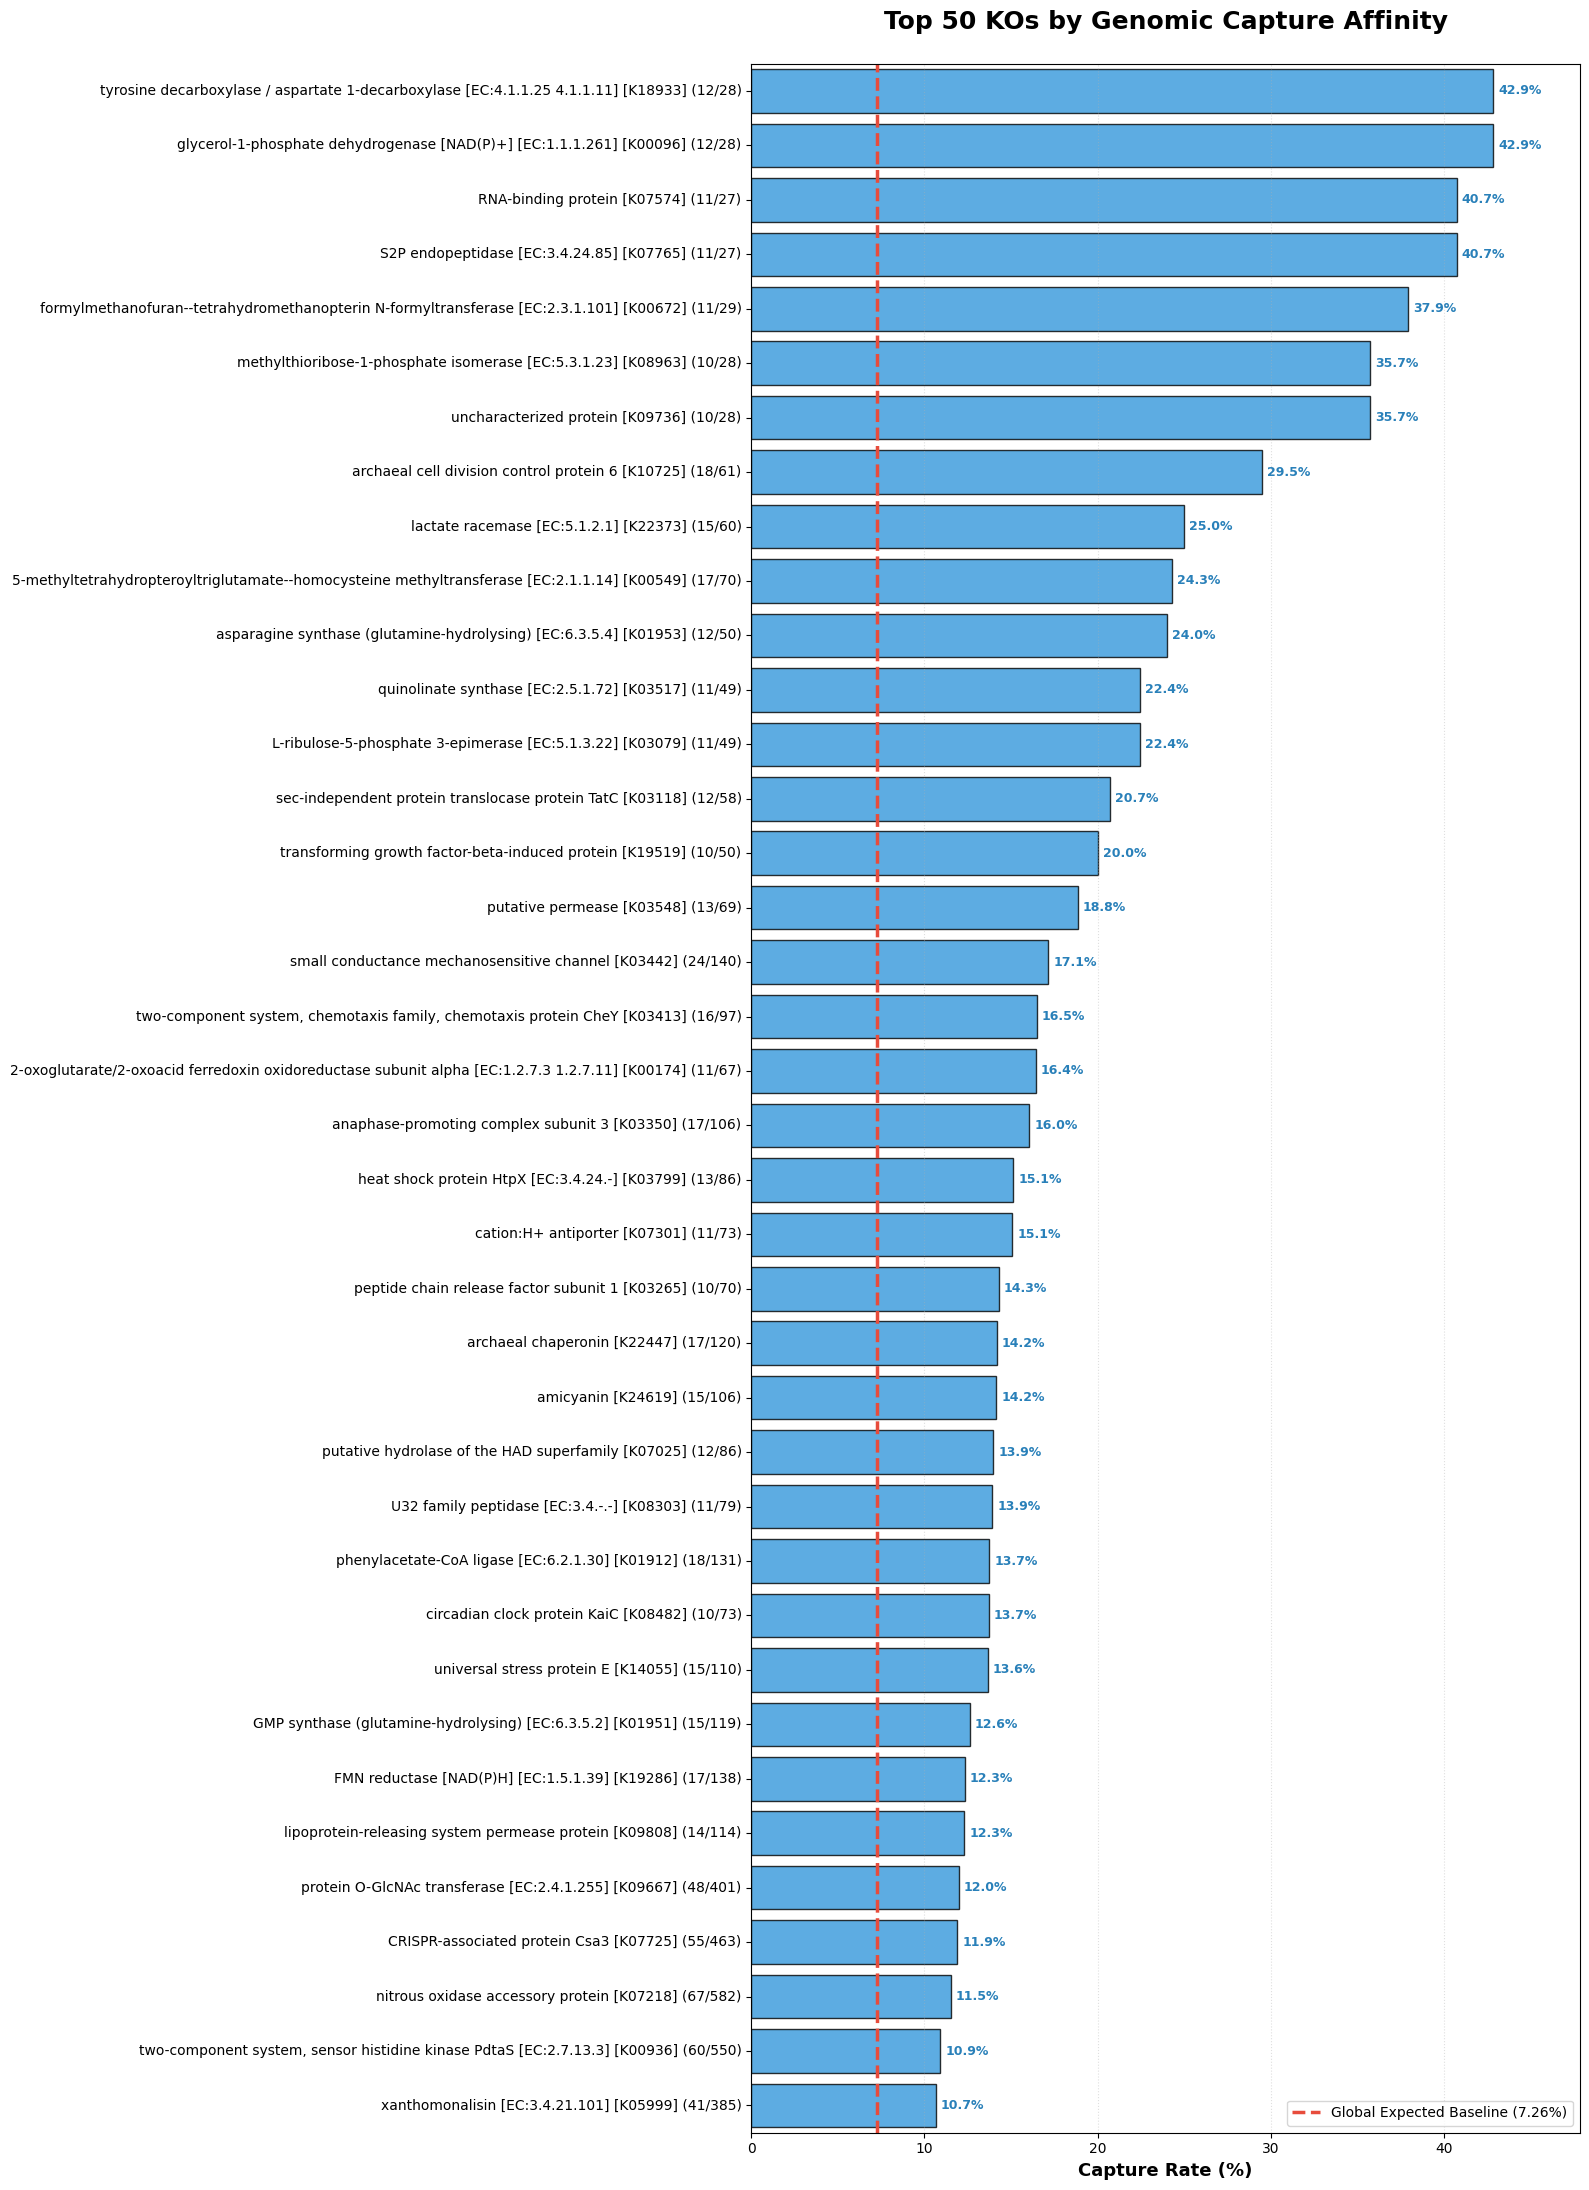

In [15]:
######################################################
#### Plot KOs with most frequent TRs next to them ####
######################################################


def plot_ko_capture_bars_from_zero(stats_df, top_n=50, min_hits=10):
    """
    Creates a bar plot where bars start at 0.
    Fixes truncated y-axis labels.
    """
    plot_df = stats_df.copy()
    
    # Robust Column Detection for definitions
    def_cols = [c for c in plot_df.columns if 'KO_definition' in c]
    if def_cols:
        plot_df['KO_definition'] = plot_df[def_cols[0]]
    else:
        plot_df['KO_definition'] = plot_df['KO']

    # Convert numeric columns
    plot_df['P_value_numeric'] = pd.to_numeric(plot_df['P_value_numeric'], errors='coerce')
    plot_df['Capture_Rate_%'] = pd.to_numeric(plot_df['Capture_Rate_%'], errors='coerce')
    plot_df['Exp_Capture_Rate_%'] = pd.to_numeric(plot_df['Exp_Capture_Rate_%'], errors='coerce')
    plot_df['KO_definition'] = plot_df['KO_definition'].fillna(plot_df['KO'])
    
    # Filter for Enriched & Significant
    filtered = plot_df[
        (plot_df['P_value_numeric'] < 0.05) & 
        (plot_df['Observed_Hits'] >= min_hits) &
        (plot_df['Status'] == 'Enriched')
    ].copy()
    
    filtered = filtered.sort_values('Capture_Rate_%', ascending=False).head(top_n)
    
    if filtered.empty:
        print(f"No significant enriched KOs found.")
        return

    # --- FIX 1: Remove the [:50] slice to show full text ---
    filtered['Label'] = filtered.apply(
        lambda x: f"{str(x['KO_definition'])} [{x['KO']}] ({int(x['Observed_Hits'])}/{int(x['Total_KO_in_Genomes'])})", 
        axis=1
    )

    # Plotting
    fig_height = 14 if top_n <= 30 else 22 # Slightly taller to prevent text crowding
    fig, ax = plt.subplots(figsize=(16, fig_height)) # Slightly wider figure
    
    expected_val = filtered['Exp_Capture_Rate_%'].iloc[0]
    y_pos = np.arange(len(filtered))

    bars = ax.barh(y=y_pos, 
                   width=filtered['Capture_Rate_%'], 
                   left=0,
                   height=0.8, 
                   color='#3498db', 
                   edgecolor='black',
                   alpha=0.8)

    ax.set_yticks(y_pos)
    # --- FIX 2: Set labels with specific alignment ---
    ax.set_yticklabels(filtered['Label'], fontsize=10, va='center')
    
    ax.invert_yaxis()
    ax.set_ylim(len(filtered) - 0.5, -0.5)

    # Draw the baseline
    ax.axvline(x=expected_val, color='#e74c3c', linestyle='--', linewidth=2.5, 
                label=f'Global Expected Baseline ({expected_val:.2f}%)')

    # Add numeric labels at the end of bars
    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.3, 
                 bar.get_y() + bar.get_height()/2,
                 f'{width:.1f}%',
                 va='center', fontsize=9, fontweight='bold', color='#2980b9')

    ax.set_title(f'Top {top_n} KOs by Genomic Capture Affinity', fontsize=18, fontweight='bold', pad=25)
    ax.set_xlabel('Capture Rate (%)', fontsize=13, fontweight='bold')
    ax.set_xlim(0, max(filtered['Capture_Rate_%'].max() + 5, expected_val + 5))
    
    ax.grid(axis='x', linestyle=':', alpha=0.4)
    ax.legend(loc='lower right')
    
    # --- FIX 3: Force layout to respect the long y-axis text ---
    plt.tight_layout()
    # If labels are STILL cut off, manually adjust the left margin:
    # fig.subplots_adjust(left=0.4) 
    
    plt.savefig(f"KO_Capture_FullText_{top_n}.pdf", dpi=300, bbox_inches='tight')
    plt.show()

# Run the plot
plot_ko_capture_bars_from_zero(capture_stats_final, top_n=50, min_hits=10)

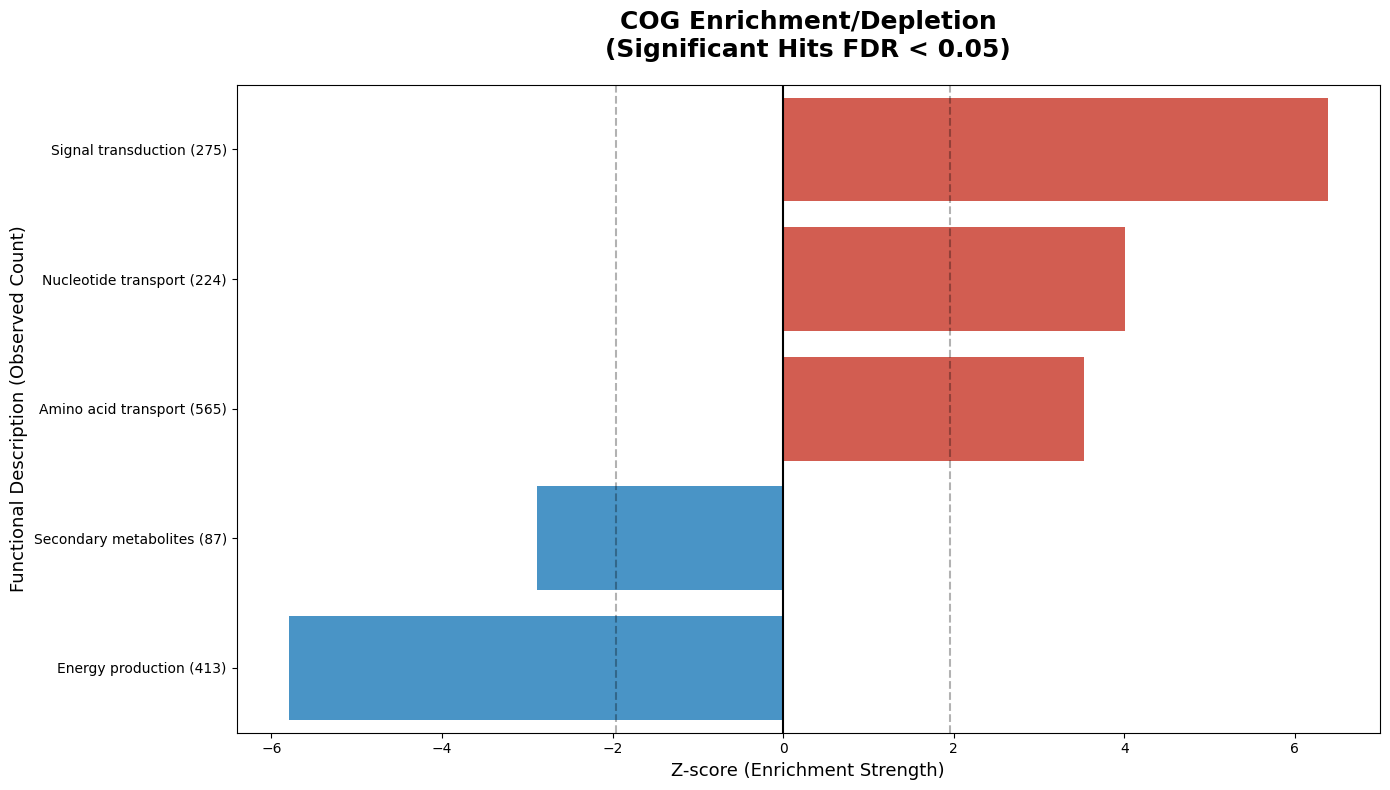

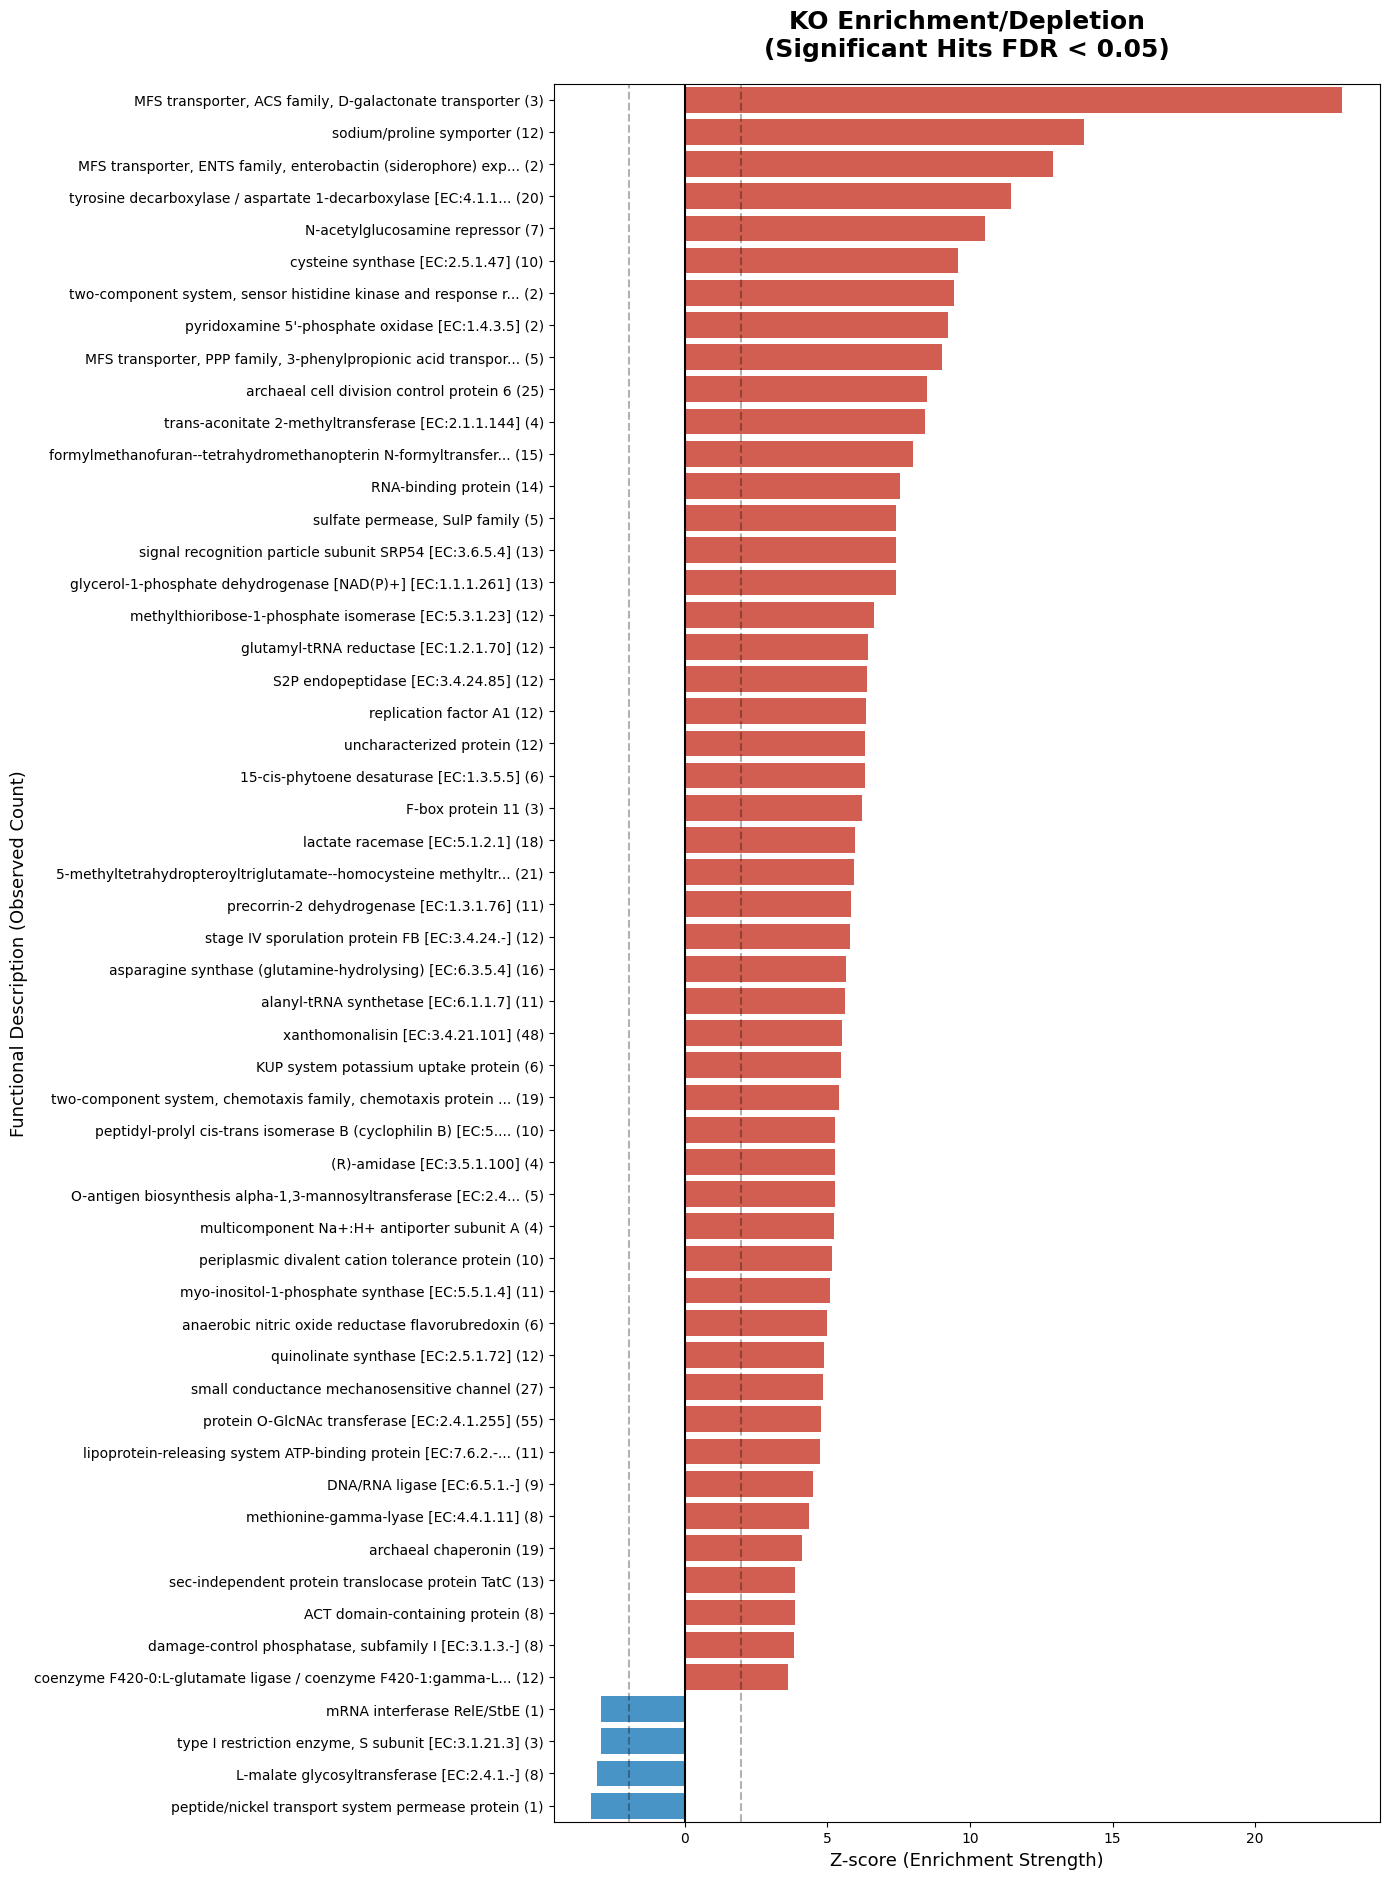

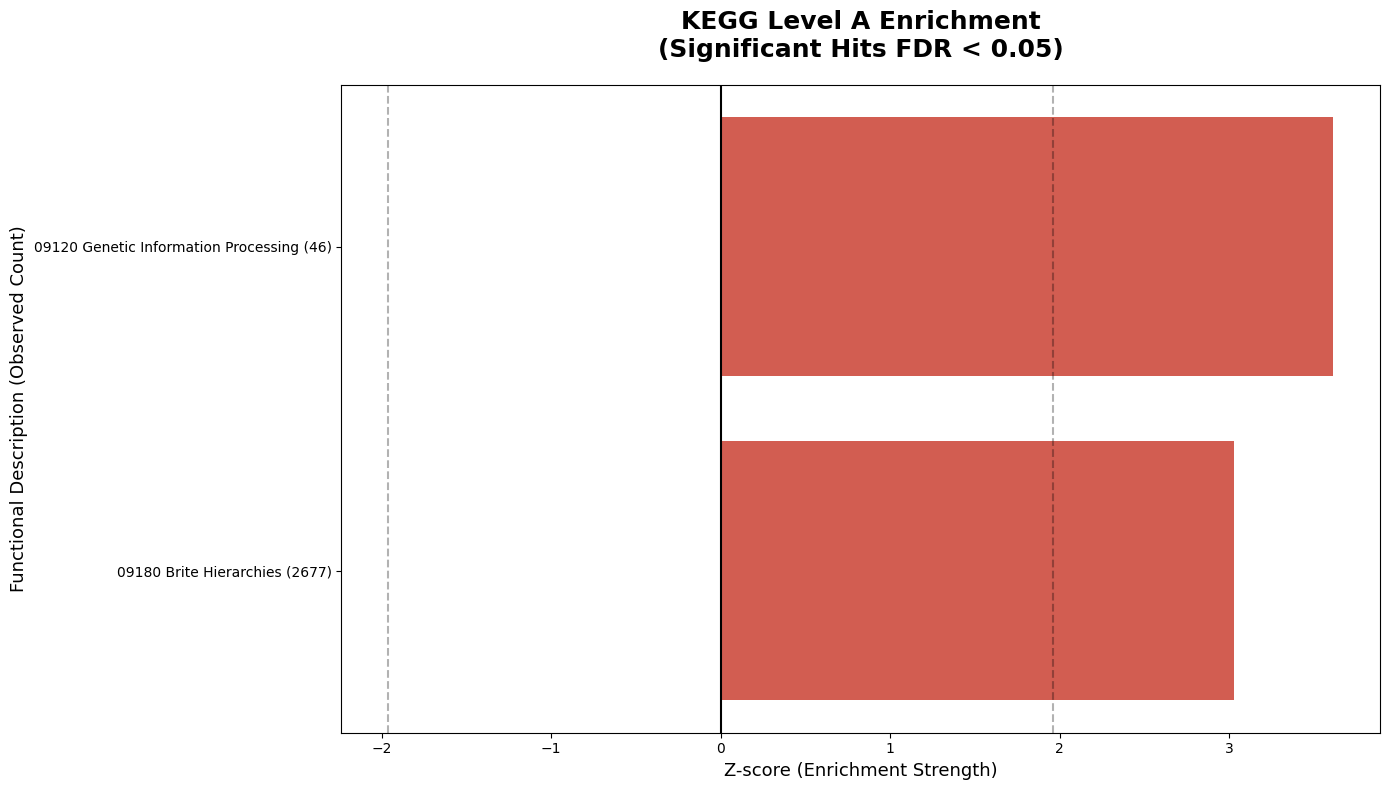

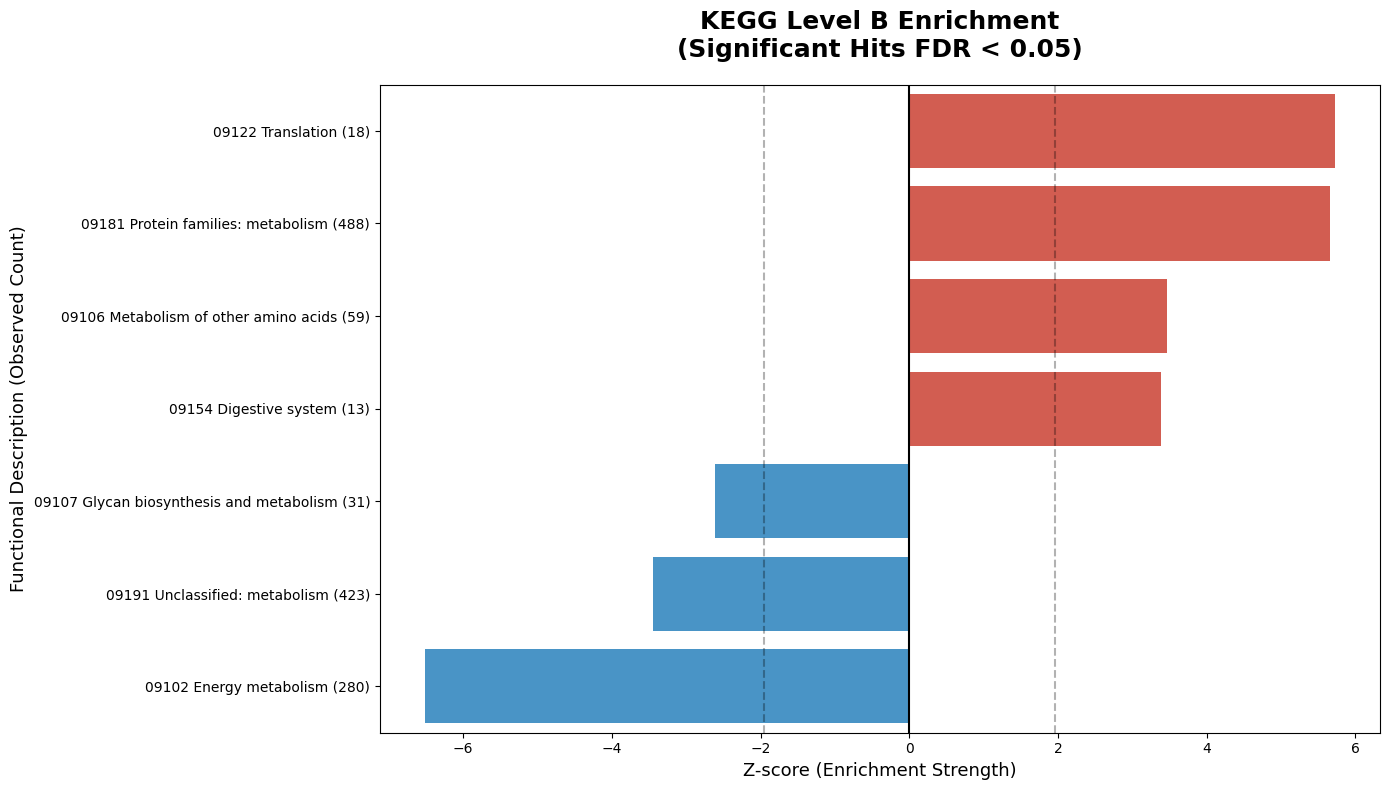

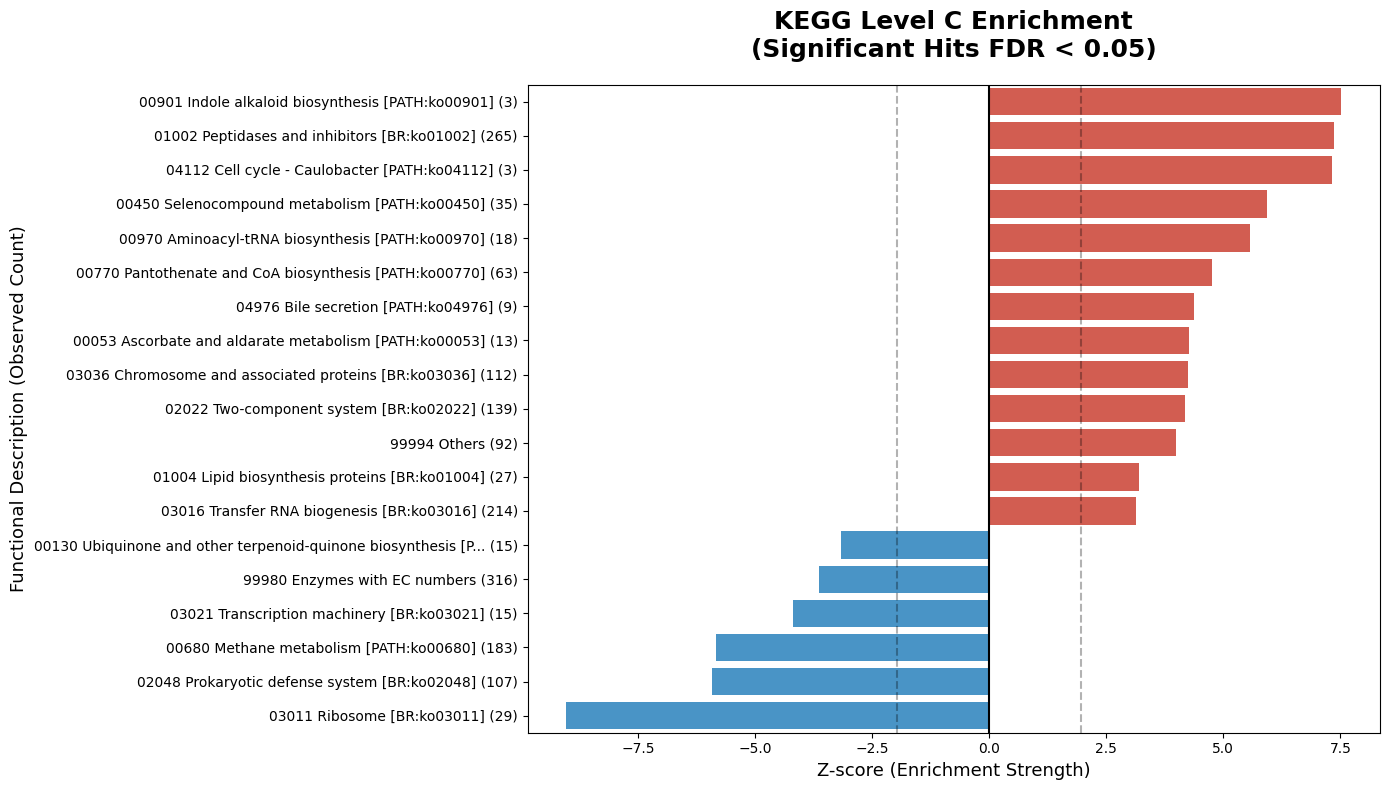

In [16]:
##################################################
##### Plot the enrichment/depletion analysis #####
##################################################

# --- 1. CLEAN MERGE FOR KO DEFINITIONS ---
# We do this once outside the function to ensure ko_stats_final is ready
if 'ko_stats_final' in globals():
    # Drop any existing definition columns to avoid ._x ._y suffixing
    cols_to_clear = ['KO_definition', 'KO_definition_x', 'KO_definition_y', 'KO']
    ko_stats_final = ko_stats_final.drop(columns=[c for c in cols_to_clear if c in ko_stats_final.columns])
    
    # Merge fresh definitions
    ko_defs = annotations[['KO', 'KO_definition']].drop_duplicates(subset=['KO'])
    ko_stats_final = pd.merge(ko_stats_final, ko_defs, left_on='Category', right_on='KO', how='left')

# --- 2. UPDATED PLOTTING FUNCTION ---
def plot_diverging_enrichment(stats_df, title, filename, top_n_enriched=50, top_n_depleted=10, is_cog=False, is_ko=False):
    plot_df = stats_df.copy()
    
    # Standard mapping for COG
    cog_names = {'J': 'Translation', 'A': 'RNA processing', 'K': 'Transcription', 
                 'L': 'Replication/Repair', 'D': 'Cell cycle', 'V': 'Defense mechanisms',
                 'T': 'Signal transduction', 'M': 'Cell wall/membrane', 'N': 'Cell motility',
                 'U': 'Intracellular trafficking', 'O': 'Posttranslational mod', 'C': 'Energy production',
                 'G': 'Carbohydrate transport', 'E': 'Amino acid transport', 'F': 'Nucleotide transport',
                 'H': 'Coenzyme transport', 'I': 'Lipid transport', 'P': 'Inorganic ion transport',
                 'Q': 'Secondary metabolites', 'R': 'General function prediction', 'S': 'Function unknown'}

    # Ensure numeric types
    plot_df['FDR_P_adj'] = pd.to_numeric(plot_df['FDR_P_adj'], errors='coerce')
    plot_df['Z_score'] = pd.to_numeric(plot_df['Z_score'], errors='coerce')
    
    # Filter for significance and non-unknowns
    filtered = plot_df[(plot_df['Category'] != 'Unknown') & (plot_df['FDR_P_adj'] < 0.05)].copy()
    if filtered.empty: 
        return print(f"No significant results for {title}")

    # Sorting
    filtered = filtered.sort_values('Z_score', ascending=False)
    top_plot = pd.concat([filtered.head(top_n_enriched), filtered.tail(top_n_depleted)]).drop_duplicates()
    
    # Assign Descriptions
    if is_cog:
        top_plot['Description'] = top_plot['Category'].map(cog_names).fillna(top_plot['Category'])
    elif is_ko:
        # Find the correct definition column regardless of merge suffixes
        def_col = [c for c in top_plot.columns if 'definition' in c.lower()]
        top_plot['Description'] = top_plot[def_col[0]].fillna(top_plot['Category']) if def_col else top_plot['Category']
    else:
        top_plot['Description'] = top_plot['Category']

    # Create Label and Color
    top_plot['Full_Label'] = top_plot.apply(
        lambda x: f"{(str(x['Description'])[:60] + '...') if len(str(x['Description'])) > 60 else x['Description']} ({int(x['Observed_Count'])})", 
        axis=1
    )
    top_plot['color'] = np.where(top_plot['Z_score'] > 0, '#e74c3c', '#3498db')
    
    # Dynamic Figure Sizing
    fig_height = max(8, len(top_plot) * 0.35)
    fig, ax = plt.subplots(figsize=(14, fig_height))
    
    # Plot bars with tight height
    sns.barplot(data=top_plot, x='Z_score', y='Full_Label', palette=top_plot['color'].tolist(), ax=ax, hue='Full_Label', legend=False)
    
    # --- TIGHT LAYOUT FIXES ---
    # Set y-axis limits to eliminate white space at top/bottom
    ax.set_ylim(len(top_plot) - 0.5, -0.5)
    
    # Vertical lines for significance thresholds (Z > 1.96 is ~ p < 0.05)
    ax.axvline(x=1.96, color='black', linestyle='--', alpha=0.3)
    ax.axvline(x=-1.96, color='black', linestyle='--', alpha=0.3)
    ax.axvline(x=0, color='black', linewidth=1.5)
    
    ax.set_title(f'{title}\n(Significant Hits FDR < 0.05)', fontsize=18, fontweight='bold', pad=20)
    ax.set_xlabel('Z-score (Enrichment Strength)', fontsize=13)
    ax.set_ylabel('Functional Description (Observed Count)', fontsize=13)
    
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

# --- CALL THE UPDATED PLOTS ---

# 1. COG Plot
plot_diverging_enrichment(cog_stats_final, "COG Enrichment/Depletion", "COG_plot_desc.pdf", is_cog=True)

# 2. KO Plot
plot_diverging_enrichment(ko_stats_final, "KO Enrichment/Depletion", "KO_plot_desc.pdf", is_ko=True, top_n_enriched=50)

# 3. KEGG Level Plots
plot_diverging_enrichment(level_a_stats, "KEGG Level A Enrichment", "KEGG_A_plot.pdf")
plot_diverging_enrichment(level_b_stats, "KEGG Level B Enrichment", "KEGG_B_plot.pdf")
plot_diverging_enrichment(level_c_stats, "KEGG Level C Enrichment", "KEGG_C_plot.pdf")

In [19]:
##################################################################################################
#### Extract the genbank regions of a KO of interest to visualize them as a clinker alignment ####
##################################################################################################

def extract_ko_with_robust_pairing(target_ko, output_root, gbk_dir, bed_dir, 
                                   annotations_df, neighbors_df, window=5000): 
    
    # 1. Setup Directories
    ko_dir = os.path.join(output_root, target_ko)
    paths = {
        "all": os.path.join(ko_dir, "ko_all"), 
        "trs": os.path.join(ko_dir, "ko_TRs_only")
    }
    for p in paths.values(): 
        os.makedirs(p, exist_ok=True)

    neighbor_ids = set(neighbors_df[neighbors_df['KO'] == target_ko]['protein_id'])
    
    # 2. Flexible File Pairing
    bed_paths = sorted(glob.glob(os.path.join(bed_dir, "*.bed")))
    gbk_paths = sorted(glob.glob(os.path.join(gbk_dir, "*.g*z")))
    
    file_pairs = []
    for b in bed_paths:
        # Use a more flexible prefix (everything before the first dot)
        b_name = os.path.basename(b)
        prefix = b_name.split('.')[0] 
        
        # Find any GBK that contains that prefix
        match = [g for g in gbk_paths if prefix in os.path.basename(g)]
        if match:
            file_pairs.append({'prefix': prefix, 'bed': b, 'gbk': match[0]})

    if not file_pairs:
        print("Error: No BED/GBK pairs found. Check your file naming.")
        return

    print(f"Found {len(file_pairs)} pairs. Starting extraction for {target_ko}...")

    # 3. Process each pair
    for pair in file_pairs:
        genome_acc = pair['prefix']
        
        # Filter hits for this genome
        genome_hits = annotations_df[(annotations_df['genome_acc'].str.contains(genome_acc)) & 
                                     (annotations_df['KO'] == target_ko)]
        if genome_hits.empty:
            continue

        # Load BED data
        try:
            df_bed = pd.read_csv(pair['bed'], sep='\t', header=None, usecols=[0, 1, 2, 3],
                                 names=['chrom', 'start', 'end', 'id'])
        except Exception as e:
            print(f"Skipping BED {pair['bed']}: {e}")
            continue

        with gzip.open(pair['gbk'], "rt") as handle:
            for record in SeqIO.parse(handle, "genbank"):
                # Filter TRs for this contig
                contig_trs = df_bed[df_bed['chrom'].astype(str) == str(record.id)]

                for feature in record.features:
                    if feature.type == "CDS":
                        p_id = feature.qualifiers.get('protein_id', [None])[0]
                        l_tag = feature.qualifiers.get('locus_tag', [None])[0]
                        
                        # Check if this is our target
                        if any(i in list(genome_hits['protein_id']) for i in [p_id, l_tag] if i):
                            
                            # Calculate window
                            f_start = int(feature.location.start)
                            f_end = int(feature.location.end)
                            abs_start = max(0, f_start - window)
                            abs_end = min(len(record.seq), f_end + window)
                            
                            # SLICE
                            sub_record = record[abs_start:abs_end]
                            sub_record.annotations["molecule_type"] = "DNA"
                            
                            # 4. INJECT TRs (Gene + CDS combo for Clinker visibility)
                            if not contig_trs.empty:
                                overlaps = contig_trs[(contig_trs['end'] > abs_start) & 
                                                      (contig_trs['start'] < abs_end)]
                                
                                for _, tr in overlaps.iterrows():
                                    rel_start = max(0, int(tr['start']) - abs_start)
                                    rel_end = min(abs_end - abs_start, int(tr['end']) - abs_start)
                                    
                                    # Ensure unique ID
                                    tr_tag = f"TR_{genome_acc}_{tr['id']}"
                                    
                                    # Create features
                                    # We use both so Clinker identifies the 'gene' but draws the 'CDS'
                                    common_quals = {
                                        "gene": [f"TR_{tr['id']}"],
                                        "locus_tag": [tr_tag],
                                        "note": [f"TR_ID:{tr['id']}"],
                                        "color": ["#FF0000"]
                                    }
                                    
                                    sub_record.features.append(SeqFeature(
                                        FeatureLocation(rel_start, rel_end),
                                        type="gene", qualifiers=common_quals))
                                    
                                    sub_record.features.append(SeqFeature(
                                        FeatureLocation(rel_start, rel_end),
                                        type="CDS", qualifiers={**common_quals, 
                                                               "product": ["Repeat"], 
                                                               "translation": [""]}))

                            # 5. Save
                            target_id = p_id if p_id else l_tag
                            out_name = f"{genome_acc}_{target_id}.gbk"
                            
                            SeqIO.write(sub_record, os.path.join(paths['all'], out_name), "genbank")
                            if (p_id and p_id in neighbor_ids) or (l_tag and l_tag in neighbor_ids):
                                SeqIO.write(sub_record, os.path.join(paths['trs'], out_name), "genbank")

    print(f"Extraction complete for {target_ko}.")
    
# --- RUN ---
extract_ko_with_robust_pairing(
    target_ko="K00549", 
    output_root="/cluster/project/umbiol/projects/methanogens/methanosarcina/genomes/TR_neighborhood/KO_Extractions", 
    gbk_dir="/cluster/project/umbiol/projects/methanogens/methanosarcina/raw_data_ncbi/geneBank_files/99_dereplicated/", 
    bed_dir="/cluster/project/umbiol/projects/methanogens/methanosarcina/genomes/TR_output/raw_output/bed_files/", 
    annotations_df=annotations_filtered, 
    neighbors_df=clean_results_df
)

Found 28 pairs. Starting extraction for K00549...
Extraction complete for K00549.


In [22]:
##########################################################################################
##### Calculate clinker alignment for KO of interest, based on the extracted regions #####
##########################################################################################

def run_clinker_for_ko(target_ko, gbk_root_dir, output_root_dir):
    clinker_bin = "/cluster/project/umbiol/software/venvs/clinker/bin/clinker"
    input_ko_dir = os.path.join(gbk_root_dir, target_ko)
    final_output_path = os.path.join(output_root_dir, target_ko)
    
    for sub in ["ko_all", "ko_TRs_only"]:
        source_path = os.path.join(input_ko_dir, sub)
        current_out_dir = os.path.join(final_output_path, sub)
        os.makedirs(current_out_dir, exist_ok=True)
        
        gbk_files = sorted(list(set(glob.glob(os.path.join(source_path, "*.gbk")))))

        if not gbk_files:
            print(f"Skipping {sub}: No .gbk files found in {source_path}")
            continue

        out_base = os.path.join(current_out_dir, f"{target_ko}_{sub}")
        out_html = f"{out_base}_plot.html"
        out_session = f"{out_base}_session.json"

        if os.path.exists(out_session): os.remove(out_session)

        try:
            print(f"\n--- Running Clinker for {target_ko} ({sub}) ---")
            subprocess.run([
                clinker_bin] + gbk_files + [
                "-p", out_html,
                "-s", out_session,
                "-f"
            ], check=True)
            
            if os.path.exists(out_session):
                with open(out_session, 'r') as f:
                    data = json.load(f)
                
                tr_group_name = "Tandem_Repeat"
                if "groups" not in data: data["groups"] = []
                
                # 1. Update gene group assignments with TYPE CHECKING
                for cluster in data.get("clusters", []):
                    if not isinstance(cluster, dict): continue  # Skip if cluster is a string
                    for locus in cluster.get("loci", []):
                        if not isinstance(locus, dict): continue
                        for gene in locus.get("genes", []):
                            if not isinstance(gene, dict): continue # Fixes the 'str' error
                            
                            # Check name, label, or uid for "TR"
                            name = gene.get("name") or gene.get("label") or ""
                            if "TR" in str(name):
                                gene["group"] = tr_group_name
                
                # 2. Ensure the group has the color Red
                found_group = False
                for group in data["groups"]:
                    if isinstance(group, dict) and group.get("name") == tr_group_name:
                        group["color"] = "#FF0000"
                        found_group = True
                
                if not found_group:
                    data["groups"].append({"name": tr_group_name, "color": "#FF0000"})

                with open(out_session, 'w') as f:
                    json.dump(data, f)
                
                print(f"Successfully color-coded TRs in {sub} plot.")

        except Exception as e:
            print(f"Error processing {sub}: {e}")

# --- EXECUTION ---
run_clinker_for_ko(
    target_ko="K00549", 
    gbk_root_dir="/cluster/project/umbiol/projects/methanogens/methanosarcina/genomes/TR_neighborhood/KO_Extractions", 
    output_root_dir="/cluster/project/umbiol/projects/methanogens/methanosarcina/genomes/TR_neighborhood/clinker_alignments"
)


--- Running Clinker for K00549 (ko_all) ---


[09:32:21] INFO - Starting clinker
[09:32:21] INFO - Parsing files:
[09:32:21] INFO -   GCA_000007345_AAM03507.1.gbk
[09:32:21] INFO -   GCA_000007345_AAM03508.1.gbk
[09:32:21] INFO -   GCA_000007345_AAM06911.1.gbk
[09:32:21] INFO -   GCA_000969905_AKB45724.1.gbk
/cluster/software/stacks/2024-05/python-cuda/3.11.6/lib/python3.11/site-packages/Bio/Seq.py:2880: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(
[09:32:21] INFO -   GCA_000969905_AKB45725.1.gbk
[09:32:21] INFO -   GCA_000969945_AKB49198.1.gbk
[09:32:21] INFO -   GCA_000969945_AKB49199.1.gbk
[09:32:21] INFO -   GCA_000969965_AKB18042.1.gbk
[09:32:21] INFO -   GCA_000969965_AKB20233.1.gbk
[09:32:21] INFO -   GCA_000969965_AKB20234.1.gbk
[09:32:21] INFO -   GCA_000969985_AKB52950.1.gbk
[09:32:21] INFO -   GCA_000969985_AKB52951.1.gbk
[09:32:22] INFO -   GCA_000970045_AKB26673.1.gbk
[09:3

GCA_000007345_AAM03507.1 vs GCA_000007345_AAM03508.1
----------------------------------------------------
Query       Target      Identity  Similarity
AAM03505.1  AAM03505.1  1.00      1.00      
AAM03506.1  AAM03506.1  1.00      1.00      
AAM03507.1  AAM03507.1  1.00      1.00      
AAM03507.1  AAM03508.1  0.51      0.70      
AAM03508.1  AAM03507.1  0.51      0.70      
AAM03508.1  AAM03508.1  1.00      1.00      
AAM03509.1  AAM03509.1  1.00      1.00      
AAM03510.1  AAM03510.1  1.00      1.00      
AAM03510.1  AAM03511.1  0.89      0.92      
AAM03510.1  AAM03512.1  0.83      0.87      
AAM03510.1  AAM03513.1  0.80      0.90      
AAM03511.1  AAM03510.1  0.89      0.92      
AAM03511.1  AAM03511.1  1.00      1.00      
AAM03511.1  AAM03512.1  0.90      0.93      
AAM03511.1  AAM03513.1  0.86      0.93      
AAM03512.1  AAM03510.1  0.83      0.87      
AAM03512.1  AAM03511.1  0.90      0.93      
AAM03512.1  AAM03512.1  1.00      1.00      
AAM03512.1  AAM03513.1  0.90      0.97 

[09:33:02] INFO - Building clustermap.js visualisation
[09:33:02] INFO - Writing to: /cluster/project/umbiol/projects/methanogens/methanosarcina/genomes/TR_neighborhood/clinker_alignments/K00549/ko_all/K00549_ko_all_plot.html
[09:33:03] INFO - Done!



Successfully color-coded TRs in ko_all plot.

--- Running Clinker for K00549 (ko_TRs_only) ---


[09:33:06] INFO - Starting clinker
[09:33:06] INFO - Parsing files:
[09:33:06] INFO -   GCA_000007345_AAM06911.1.gbk
[09:33:06] INFO -   GCA_000969905_AKB45725.1.gbk
/cluster/software/stacks/2024-05/python-cuda/3.11.6/lib/python3.11/site-packages/Bio/Seq.py:2880: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(
[09:33:06] INFO -   GCA_000969945_AKB49198.1.gbk
[09:33:06] INFO -   GCA_000969945_AKB49199.1.gbk
[09:33:06] INFO -   GCA_000969965_AKB20233.1.gbk
[09:33:06] INFO -   GCA_000969985_AKB52950.1.gbk
[09:33:06] INFO -   GCA_000969985_AKB52951.1.gbk
[09:33:06] INFO -   GCA_000970045_AKB26673.1.gbk
[09:33:06] INFO -   GCA_000970045_AKB26674.1.gbk
[09:33:06] INFO -   GCA_000970085_AKB27724.1.gbk
[09:33:06] INFO -   GCA_000970305_AKB80981.1.gbk
[09:33:06] INFO -   GCA_000970305_AKB84017.1.gbk
[09:33:06] INFO -   GCA_000970305_AKB84018.1.gbk
[09:3

GCA_000007345_AAM06911.1 vs GCA_000969905_AKB45725.1
----------------------------------------------------
Query       Target      Identity  Similarity
AAM06911.1  AKB45724.1  0.78      0.89      
AAM06911.1  AKB45725.1  0.50      0.69      

GCA_000007345_AAM06911.1 vs GCA_000969945_AKB49198.1
----------------------------------------------------
Query       Target      Identity  Similarity
AAM06911.1  AKB49198.1  0.78      0.89      
AAM06911.1  AKB49199.1  0.50      0.69      

GCA_000007345_AAM06911.1 vs GCA_000969945_AKB49199.1
----------------------------------------------------
Query       Target      Identity  Similarity
AAM06911.1  AKB49198.1  0.78      0.89      
AAM06911.1  AKB49199.1  0.50      0.69      

GCA_000007345_AAM06911.1 vs GCA_000969965_AKB20233.1
----------------------------------------------------
Query       Target      Identity  Similarity
AAM06911.1  AKB20233.1  0.52      0.70      
AAM06911.1  AKB20234.1  0.77      0.87      

GCA_000007345_AAM06911.1 vs GCA_